# Anonimización automática de historias clínicas en español

**Integrantes:** Juan David Cuintaco · Santiago Serrano · Juan Felipe Pardo Quintana · Óscar Iván García Montañez

**Curso:** Procesamiento de Lenguaje Natural, Pontificia Universidad Javeriana

**Entrega final:** pipeline completo con MEDDOCAN y BETO

---

Este notebook desarrolla el pipeline de la propuesta, caja por caja. Cada bloque recibe una
entrada, aplica una transformación y deja una salida que usa el siguiente.

| Caja | Etapa del pipeline | Qué hace |
|---|---|---|
| 0 | Preparación | Deja listo el entorno y las rutas |
| 1 | Adquisición, exploración y limpieza | Carga y audita los 1.000 documentos |
| 2 | Etiquetado | Convierte spans de carácter en 45 etiquetas BIO |
| 3 | Seccionado y representación | Tokeniza con BETO y arma ventanas de 512 |
| 4 | Línea base | Detecta datos estructurados con reglas |
| 5 | Modelado | Entrena BETO como clasificador de tokens |
| 6 | Evaluación | Mide por documento y compara reglas, BETO y unión |
| 7 | Instanciación | Anonimiza texto nuevo y mide la fuga |
| 8 | Adaptación a Colombia | Prueba colombiana, reglas locales y aumento de datos |
| 9 | Mejoras y cambio de modelo | Postproceso, umbral de recall y RoBERTa clínico |

Para ejecutarlo en Colab: **Entorno de ejecución → Cambiar tipo de entorno → T4 GPU**.
Los datos personales del corpus MEDDOCAN son sintéticos.

> **Exportación.** Este notebook monta Google Drive al inicio y, en la **Caja 10**, guarda el
> sistema final (BETO adaptado + reglas colombianas + postproceso y umbral de la Caja 9) para
> usarlo en `02_demo_anonimizacion.ipynb` sin volver a entrenar.


In [1]:
%pip install -q "transformers>=4.46" "datasets>=3.0" "accelerate>=1.0" seqeval scikit-learn matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


> Si Colab pide reiniciar el entorno después de instalar, hazlo y vuelve a ejecutar desde la Caja 0.

## Caja 0 · Preparar el entorno

**Entra:** el repositorio con la carpeta `data/raw/`.
**Sale:** rutas, dependencias y semilla listas para repetir el experimento.
**Herramienta:** Python, PyTorch y Hugging Face.

Primero ubicamos la carpeta del proyecto. En Colab se puede clonar el repositorio o subir la
carpeta completa; el bloque siguiente busca las dos opciones. Si no encuentra los datos, los descarga
del repositorio público de MEDDOCAN en GitHub y arma `data/raw/` automáticamente.

In [2]:
# ---------------------------------------------------------------------------
# Si no existe data/raw, la construimos desde el repositorio público de MEDDOCAN
# (Plan TL, Barcelona Supercomputing Center). Así el notebook corre sin subir nada.
# ---------------------------------------------------------------------------
import glob
import os
import subprocess
from pathlib import Path

import pandas as pd

candidatos = ["data/raw/02_documentos.csv",
              "/content/meddocan-anon/data/raw/02_documentos.csv",
              "/content/drive/MyDrive/meddocan-anon/data/raw/02_documentos.csv"]

if not any(Path(c).exists() for c in candidatos):
    if not Path("SPACCC_MEDDOCAN").exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/PlanTL-GOB-ES/SPACCC_MEDDOCAN.git"], check=True)
    docs_csv, anot_csv = [], []
    for carpeta, split in [("train", "entrenamiento"), ("dev", "validación"), ("test", "prueba")]:
        for archivo in sorted(glob.glob(f"SPACCC_MEDDOCAN/corpus/{carpeta}/brat/*.txt")):
            doc_id = os.path.basename(archivo)[:-4]
            docs_csv.append({"documento": doc_id, "split": split,
                             "texto": open(archivo, encoding="utf-8").read()})
            for linea in open(archivo[:-4] + ".ann", encoding="utf-8"):
                if linea.startswith("T"):
                    _, info, texto_anotado = linea.rstrip("\n").split("\t")
                    partes = info.split()
                    anot_csv.append({"documento": doc_id, "tipo": partes[0],
                                     "caracter_inicio": int(partes[1]),
                                     "caracter_fin": int(partes[-1]),
                                     "texto_anotado": texto_anotado})
    Path("data/raw").mkdir(parents=True, exist_ok=True)
    pd.DataFrame(docs_csv).to_csv("data/raw/02_documentos.csv", sep=";", index=False, encoding="utf-8-sig")
    pd.DataFrame(anot_csv).to_csv("data/raw/01_anotaciones.csv", sep=";", index=False, encoding="utf-8-sig")
    print(f"Datos construidos desde GitHub: {len(docs_csv)} documentos, {len(anot_csv)} anotaciones")
else:
    print("Se usan los datos que ya están en data/raw")

Datos construidos desde GitHub: 1000 documentos, 22795 anotaciones


In [3]:
# En Colab, si el repositorio no está clonado:
# !git clone https://github.com/TU_USUARIO/meddocan-anon.git
# %cd meddocan-anon

import os
from pathlib import Path

if not Path("data/raw/02_documentos.csv").exists():
    for candidato in ("/content/meddocan-anon", "/content/drive/MyDrive/meddocan-anon"):
        if Path(candidato, "data/raw/02_documentos.csv").exists():
            os.chdir(candidato)
            break

BASE = Path.cwd()
assert (BASE / "data/raw/02_documentos.csv").exists(), \
    "No se encontró data/raw. Clona el repositorio o sube la carpeta meddocan-anon."

print("Directorio de trabajo:", BASE)
print("Archivos de datos:", sorted(p.name for p in (BASE / "data/raw").glob("*")))

Directorio de trabajo: /content
Archivos de datos: ['01_anotaciones.csv', '02_documentos.csv']


In [4]:
import json
import random
import re
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

# ---------------------------------------------------------------------------
# Parámetros generales del experimento
# ---------------------------------------------------------------------------
SEED = 42
MODELO = "dccuchile/bert-base-spanish-wwm-cased"  # BETO entrenado con texto en español
MAX_LEN = 512     # máximo de subpalabras por ventana (límite de BETO)
STRIDE = 128      # solape entre ventanas para no cortar entidades
EPOCHS = 10       # la validación se estabiliza alrededor de la época 8

# Cambia a True para probar todo el flujo en CPU con 8 documentos y 1 época.
MODO_RAPIDO = False

if MODO_RAPIDO:
    MAX_LEN, STRIDE, EPOCHS = 256, 64, 1

# Rutas de entrada y de salida del modelo
DATA = BASE / "data/raw"
SALIDA = BASE / ("models/rapido" if MODO_RAPIDO else "models/beto-meddocan")
SALIDA.mkdir(parents=True, exist_ok=True)

# Fijamos la semilla para que la partición y el entrenamiento sean reproducibles
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"

print("Dispositivo:", DISPOSITIVO)
print(f"max_len={MAX_LEN} | stride={STRIDE} | épocas={EPOCHS} | modo_rápido={MODO_RAPIDO}")

Dispositivo: cuda
max_len=512 | stride=128 | épocas=10 | modo_rápido=False


### Montar Google Drive

Lo montamos al inicio para que la Caja 10 pueda guardar el modelo al final sin pedir permisos
cuando ya terminó el entrenamiento. Fuera de Colab esta celda no hace nada y la exportación
se guarda en la carpeta `export/` del proyecto.

In [5]:
# ---------------------------------------------------------------------------
# Google Drive: aquí queda la exportación para la demo
# ---------------------------------------------------------------------------
NOMBRE_EXPORT = "anonimizador_beto_co"   # carpeta (y zip) que lee el notebook de demo
GUARDAR_ZIP = True                        # además de la carpeta, deja un .zip

try:
    from google.colab import drive
    drive.mount("/content/drive")
    RAIZ_EXPORT = Path("/content/drive/MyDrive/meddocan-anon/export")
except ImportError:
    RAIZ_EXPORT = BASE / "export"

RAIZ_EXPORT.mkdir(parents=True, exist_ok=True)
print("La exportación se guardará en", RAIZ_EXPORT / NOMBRE_EXPORT)

Mounted at /content/drive
La exportación se guardará en /content/drive/MyDrive/meddocan-anon/export/anonimizador_beto_co


## Caja 1 · Adquirir, explorar y limpiar

**Entra:** `02_documentos.csv` y `01_anotaciones.csv`.
**Sale:** 1.000 documentos con sus entidades y offsets verificados.
**Herramienta:** pandas y estadística descriptiva.

En este proyecto la limpieza es conservadora. No pasamos a minúsculas, no quitamos tildes,
dígitos ni puntuación: las etiquetas dependen de esos caracteres (`@` en correos, `/` en
fechas, mayúsculas en nombres). Leemos el texto tal como viene para que los offsets sigan
apuntando al lugar correcto.

In [6]:
# ---------------------------------------------------------------------------
# Carga de los dos archivos del corpus
# 02_documentos.csv: una fila por historia clínica, con el texto completo.
# 01_anotaciones.csv: una fila por entidad, con su tipo y sus offsets.
# ---------------------------------------------------------------------------
docs = pd.read_csv(DATA / "02_documentos.csv", sep=";", encoding="utf-8-sig")
anot = pd.read_csv(DATA / "01_anotaciones.csv", sep=";", encoding="utf-8-sig")
anot["caracter_inicio"] = anot["caracter_inicio"].astype(int)
anot["caracter_fin"] = anot["caracter_fin"].astype(int)

# Agrupamos las entidades por documento para no recorrer la tabla completa cada vez.
entidades_por_doc = defaultdict(list)
for a in anot.itertuples(index=False):
    entidades_por_doc[a.documento].append({
        "start": a.caracter_inicio,
        "end": a.caracter_fin,
        "type": a.tipo,
        "text": a.texto_anotado,
    })

# Cada registro reúne el texto y todas sus entidades anotadas.
registros = [
    {
        "id": d.documento,
        "split": d.split,
        "text": d.texto,
        "entities": entidades_por_doc.get(d.documento, []),
    }
    for d in docs.itertuples(index=False)
]
tipos = sorted(anot["tipo"].unique())

print(f"Documentos: {len(registros)} | Anotaciones: {len(anot)} | Tipos: {len(tipos)}")

Documentos: 1000 | Anotaciones: 22795 | Tipos: 22


In [7]:
# ---------------------------------------------------------------------------
# Auditoría rápida: tamaños, offsets y longitudes
# ---------------------------------------------------------------------------
filas = []
for split in ("entrenamiento", "validación", "prueba"):
    rs = [r for r in registros if r["split"] == split]
    filas.append({
        "split": split,
        "documentos": len(rs),
        "entidades": sum(len(r["entities"]) for r in rs),
    })

tabla_splits = pd.DataFrame(filas)
tabla_splits["entidades_por_documento"] = (tabla_splits["entidades"] / tabla_splits["documentos"]).round(1)
display(tabla_splits)

# Comprobamos que cada anotación coincida exactamente con el texto que señala.
malos = sum(
    1 for r in registros for e in r["entities"]
    if r["text"][e["start"]:e["end"]] != e["text"]
)
largos = pd.Series([len(r["text"]) for r in registros])
multipalabra = sum(1 for r in registros for e in r["entities"] if " " in e["text"])

print("Offsets que no coinciden con el texto:", malos)
print("Caracteres por documento: media=%.0f mediana=%.0f máximo=%.0f" % (
    largos.mean(), largos.median(), largos.max()))
print(f"Entidades de varias palabras: {multipalabra} de {len(anot)} ({100*multipalabra/len(anot):.1f}%)")

,split,documentos,entidades,entidades_por_documento
0,entrenamiento,500,11333,22.7
1,validación,250,5801,23.2
2,prueba,250,5661,22.6


Offsets que no coinciden con el texto: 0
Caracteres por documento: media=2888 mediana=2707 máximo=8123
Entidades de varias palabras: 10126 de 22795 (44.4%)


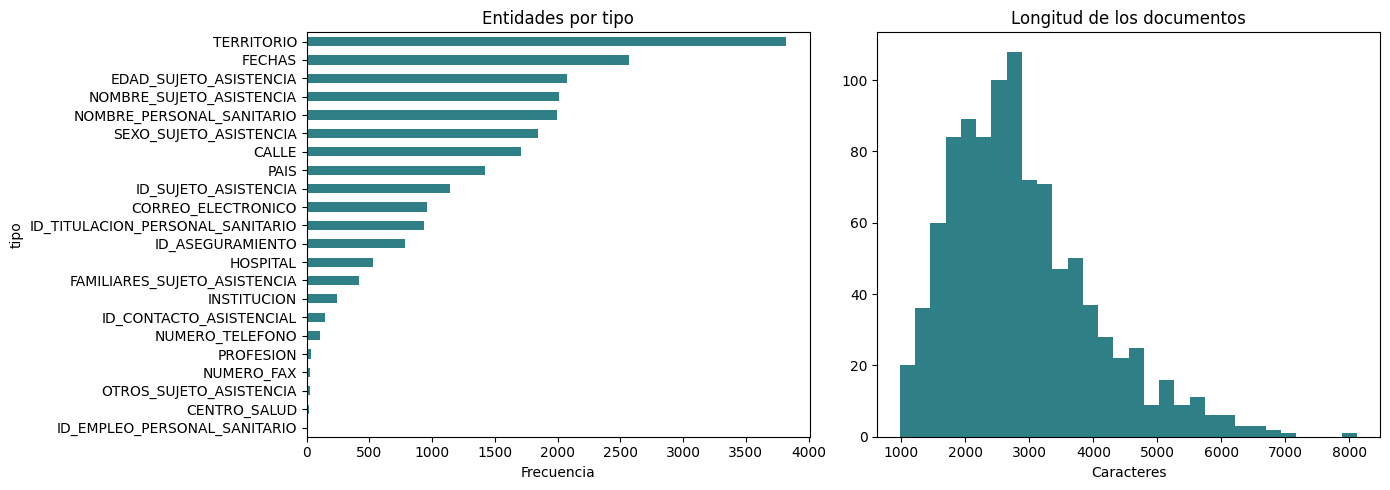

In [8]:
%matplotlib inline

# Dos vistas rápidas del corpus: desbalance entre tipos y longitud de los textos.
conteo = anot["tipo"].value_counts()
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))

conteo.sort_values().plot.barh(ax=ejes[0], color="#2F7F86")
ejes[0].set_title("Entidades por tipo")
ejes[0].set_xlabel("Frecuencia")

ejes[1].hist([len(r["text"]) for r in registros], bins=30, color="#2F7F86")
ejes[1].set_title("Longitud de los documentos")
ejes[1].set_xlabel("Caracteres")

plt.tight_layout()
plt.show()

La primera historia clínica del corpus permite ver cómo llegan los datos y cómo se ven las
anotaciones. Recordamos que los datos personales son sintéticos.

In [9]:
# Mostramos el primer documento y sus primeras anotaciones para ver el formato real.
ejemplo = registros[0]
print(ejemplo["text"][:700])

print("\nAnotaciones del documento:")
tabla_ejemplo = pd.DataFrame([
    {"texto": e["text"], "tipo": e["type"], "inicio": e["start"], "fin": e["end"]}
    for e in ejemplo["entities"]
])
display(tabla_ejemplo.head(12))

Datos del paciente.
Nombre:  Ernesto.
Apellidos: Rivera Bueno.
NHC: 368503.
NASS: 26 63514095.
Domicilio:  Calle Miguel Benitez 90.
Localidad/ Provincia: Madrid.
CP: 28016.
Datos asistenciales.
Fecha de nacimiento: 03/03/1946.
País: España.
Edad: 70 años Sexo: H.
Fecha de Ingreso: 12/12/2016.
Médico:  Ignacio Navarro Cuéllar NºCol: 28 28 70973.
Informe clínico del paciente: Paciente de 70 años de edad, minero jubilado, sin alergias medicamentosas conocidas, que presenta como antecedentes personales: accidente laboral antiguo con fracturas vertebrales y costales; intervenido de enfermedad de Dupuytren en mano derecha y by-pass iliofemoral izquierdo; Diabetes Mellitus tipo II, hipercolesterole

Anotaciones del documento:


,texto,tipo,inicio,fin
0,03/03/1946,FECHAS,215,225
1,nnavcu@hotmail.com,CORREO_ELECTRONICO,2421,2439
2,España,PAIS,2406,2412
3,Madrid,TERRITORIO,2398,2404
4,28036,TERRITORIO,2392,2397
5,"c/ del Abedul 5-7, 2º dcha",CALLE,2365,2391
6,Ignacio Navarro Cuéllar,NOMBRE_PERSONAL_SANITARIO,303,326
7,Ignacio Navarro Cuéllar,NOMBRE_PERSONAL_SANITARIO,2341,2364
8,70 años,EDAD_SUJETO_ASISTENCIA,389,396
9,28 28 70973,ID_TITULACION_PERSONAL_SANITARIO,334,345


## Caja 2 · Etiquetar: de offsets a BIO

**Entra:** spans de carácter y sus tipos.
**Sale:** 45 etiquetas (`O` + 22 tipos × `B-`/`I-`).
**Herramienta:** tokenizador de BETO con mapa de offsets.

El modelo no aprende con rangos de caracteres sino con una etiqueta por subpalabra. La regla
es: el primer token que cae dentro de la entidad recibe `B-TIPO`, los siguientes reciben
`I-TIPO` y todo lo demás queda en `O`. Los tokens especiales y las entidades cortadas por una
ventana se marcan con `-100` para que no aporten a la pérdida.

In [10]:
# 22 tipos producen 45 etiquetas: una O y un par B-/I- por cada tipo.
etiquetas = ["O"]
for t in tipos:
    etiquetas.extend([f"B-{t}", f"I-{t}"])

label2id = {etiqueta: i for i, etiqueta in enumerate(etiquetas)}
id2label = {i: etiqueta for etiqueta, i in label2id.items()}

print("Número de etiquetas:", len(etiquetas))
print("Primeras:", etiquetas[:7])
print("Últimas:", etiquetas[-4:])

Número de etiquetas: 45
Primeras: ['O', 'B-CALLE', 'I-CALLE', 'B-CENTRO_SALUD', 'I-CENTRO_SALUD', 'B-CORREO_ELECTRONICO', 'I-CORREO_ELECTRONICO']
Últimas: ['B-SEXO_SUJETO_ASISTENCIA', 'I-SEXO_SUJETO_ASISTENCIA', 'B-TERRITORIO', 'I-TERRITORIO']


In [11]:
def alinear(offsets, entidades, label2id):
    """Convierte spans de carácter en etiquetas por subpalabra.

    Para cada entidad buscamos los tokens cuyo inicio cae dentro del span.
    El primero recibe B-TIPO y los siguientes I-TIPO. Si la ventana corta la
    entidad, sus tokens se marcan con -100 para no entrenar con datos parciales.
    """
    fila = [label2id["O"] if fin > inicio else -100 for inicio, fin in offsets]

    for ent in entidades:
        ini, fin, tipo = ent["start"], ent["end"], ent["type"]
        idx = [i for i, (s, _) in enumerate(offsets) if s >= ini and s < fin]
        if not idx:
            continue

        primero, ultimo = idx[0], idx[-1]
        # Si la entidad queda cortada por el borde de la ventana, se ignora.
        if offsets[primero][0] > ini or offsets[ultimo][1] < fin:
            for i in idx:
                fila[i] = -100
            continue

        fila[primero] = label2id[f"B-{tipo}"]
        for i in idx[1:]:
            fila[i] = label2id[f"I-{tipo}"]

    return fila

Comprobamos la transformación con una frase corta que tiene un nombre y una identificación.
La tabla muestra el token, su posición y la etiqueta que recibe.

In [12]:
from transformers import AutoTokenizer

# BETO parte las palabras en subpalabras; el mapa de offsets dice a qué parte
# del texto original corresponde cada una.
tokenizer = AutoTokenizer.from_pretrained(MODELO)
print("¿Tokenizador rápido?", tokenizer.is_fast)

frase = "Nombre: Ernesto. NHC: 368503."
spans_frase = [
    {"start": 8, "end": 15, "type": "NOMBRE_SUJETO_ASISTENCIA"},
    {"start": 22, "end": 28, "type": "ID_SUJETO_ASISTENCIA"},
]

cod = tokenizer(frase, return_offsets_mapping=True, add_special_tokens=True)
etiquetas_frase = alinear(cod["offset_mapping"], spans_frase, label2id)

# La tabla permite comprobar que la etiqueta cae en las subpalabras correctas.
filas = []
for token_id, (ini, fin), et in zip(cod["input_ids"], cod["offset_mapping"], etiquetas_frase):
    if fin > ini:
        filas.append({
            "token": tokenizer.decode([token_id]),
            "inicio": ini,
            "fin": fin,
            "etiqueta": id2label[et],
        })

display(pd.DataFrame(filas))

config.json:   0%|          | 0.00/648 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/364 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/242k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/480k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/134 [00:00<?, ?B/s]

¿Tokenizador rápido? True


,token,inicio,fin,etiqueta
0,Nombre,0,6,O
1,:,6,7,O
2,Ernesto,8,15,B-NOMBRE_SUJETO_ASISTENCIA
3,.,15,16,O
4,NH,17,19,O
5,##C,19,20,O
6,:,20,21,O
7,36,22,24,B-ID_SUJETO_ASISTENCIA
8,##85,24,26,I-ID_SUJETO_ASISTENCIA
9,##03,26,28,I-ID_SUJETO_ASISTENCIA


## Caja 3 · Seccionar y representar

**Entra:** documentos completos y sus entidades.
**Sale:** ventanas tokenizadas con sus etiquetas.
**Herramienta:** tokenizador BETO y ventanas de 512 tokens con solape de 128.

Más de la mitad de los documentos supera los 512 tokens. Partimos cada uno en ventanas y
usamos solape para que ninguna entidad quede cortada justo en el borde. Si una entidad cae en
el límite, se ignora en esa ventana y se recupera completa en la siguiente.

In [13]:
def codificar(registro, tokenizer, max_len, stride, label2id):
    """Tokeniza un documento y devuelve una fila por ventana.

    Usamos return_overflowing_tokens para partir el texto largo y
    return_offsets_mapping para conservar la posición de cada subpalabra.
    """
    cod = tokenizer(
        registro["text"],
        max_length=max_len,
        stride=stride,
        truncation=True,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        add_special_tokens=True,
    )

    filas = []
    for ids, mask, offs in zip(cod["input_ids"], cod["attention_mask"], cod["offset_mapping"]):
        filas.append({
            "input_ids": ids,
            "attention_mask": mask,
            "labels": alinear(offs, registro["entities"], label2id),
            "offsets": [list(o) for o in offs],
            "doc_id": registro["id"],
        })
    return filas

In [14]:
ejemplo = registros[0]
ventanas = codificar(ejemplo, tokenizer, MAX_LEN, STRIDE, label2id)
print(f"Documento {ejemplo['id']}: {len(ejemplo['text'])} caracteres, "
      f"{len(ejemplo['entities'])} entidades, {len(ventanas)} ventanas")
print("Tokens por ventana:", [len(v["input_ids"]) for v in ventanas])

cubiertas = sum(
    1 for e in ejemplo["entities"]
    if any(any(s >= e["start"] and s < e["end"] for s, _ in v["offsets"]) for v in ventanas)
)
print(f"Entidades con al menos un token: {cubiertas}/{len(ejemplo['entities'])}")

Documento S0004-06142005000500011-1: 2441 caracteres, 21 entidades, 2 ventanas
Tokens por ventana: [512, 247]
Entidades con al menos un token: 21/21


In [15]:
def verificar_alineacion(registros, tokenizer, label2id, id2label, n=50):
    faltan = 0
    for r in registros[:n]:
        filas = codificar(r, tokenizer, MAX_LEN, STRIDE, label2id)
        for ent in r["entities"]:
            encontrada = False
            for fila in filas:
                idx = [i for i, (s, _) in enumerate(fila["offsets"])
                       if s >= ent["start"] and s < ent["end"]]
                if not idx:
                    continue
                etiqueta = fila["labels"][idx[0]]
                if etiqueta != -100 and id2label[etiqueta] == f"B-{ent['type']}":
                    encontrada = True
                    break
            faltan += not encontrada
    return faltan

print("Entidades sin etiqueta B- en 50 documentos:",
      verificar_alineacion(registros, tokenizer, label2id, id2label))

Entidades sin etiqueta B- en 50 documentos: 0


In [16]:
from datasets import Dataset

def construir(split, con_offsets=False, limite=None):
    """Arma un Dataset de Hugging Face con las ventanas de un split.

    En entrenamiento y validación no necesitamos offsets. En prueba sí los
    conservamos para reconstruir las entidades completas por documento.
    """
    rs = [r for r in registros if r["split"] == split]
    if limite:
        rs = rs[:limite]

    filas = []
    for r in rs:
        for fila in codificar(r, tokenizer, MAX_LEN, STRIDE, label2id):
            if not con_offsets:
                fila.pop("offsets")
            filas.append(fila)
    return Dataset.from_list(filas)

limites = {"entrenamiento": 8, "validación": 4, "prueba": 4} if MODO_RAPIDO else {}

train_ds = construir("entrenamiento", limite=limites.get("entrenamiento"))
val_ds = construir("validación", limite=limites.get("validación"))
test_ds = construir("prueba", con_offsets=True, limite=limites.get("prueba"))

print(f"Ventanas: train={len(train_ds)} val={len(val_ds)} test={len(test_ds)}")

Ventanas: train=1021 val=538 test=501


## Caja 4 · Línea base con reglas

**Entra:** texto clínico.
**Sale:** spans detectados para tipos con estructura fija.
**Herramienta:** expresiones regulares.

Las reglas cubren correos, fechas, edad, sexo, identificadores que aparecen después de una
etiqueta (`NHC:`, `NASS:`, `NºCol:`, `CP:`) y teléfonos o fax cuando el documento los anuncia.
No intentan detectar nombres, calles ni hospitales: eso queda para BETO. Esta línea base sirve
para saber cuánto aporta el modelo y en qué tipos conviene combinarlo.

In [17]:
# ---------------------------------------------------------------------------
# Reglas para los tipos con estructura fija
# ---------------------------------------------------------------------------
REGLAS = [
    # Correos electrónicos
    ("CORREO_ELECTRONICO", re.compile(r"[\w.+-]+@[\w-]+\.[\w.-]+")),
    # Fechas numéricas: 03/03/1946, 3-3-46, 2016-03-03
    ("FECHAS", re.compile(r"\b\d{1,2}[/-]\d{1,2}[/-]\d{2,4}\b")),
    # Edad: "70 años"
    ("EDAD_SUJETO_ASISTENCIA", re.compile(r"\b\d{1,3}\s*años\b", re.I)),
    # Sexo cuando aparece como "Sexo: H" o "Sexo: M"
    ("SEXO_SUJETO_ASISTENCIA", re.compile(r"\bSexo:\s*([HM])\b", re.I)),
    # Identificadores que siguen a una etiqueta conocida del documento
    ("ID_SUJETO_ASISTENCIA", re.compile(r"\bNHC:\s*([0-9][0-9 ]{2,})")),
    ("ID_ASEGURAMIENTO", re.compile(r"\bNASS:\s*([0-9][0-9 ]{2,})")),
    ("ID_TITULACION_PERSONAL_SANITARIO", re.compile(r"\bN[ºo]Col:\s*([0-9][0-9 ]{2,})")),
    ("TERRITORIO", re.compile(r"\bCP:\s*(\d{5})\b")),
    # Teléfono y fax cuando el documento los anuncia
    ("NUMERO_TELEFONO", re.compile(r"\bTel[eé]fono:\s*([+\d][\d\s-]{6,}\d)")),
    ("NUMERO_FAX", re.compile(r"\bFax:\s*([+\d][\d\s-]{6,}\d)")),
]

def spans_regex(texto):
    """Devuelve los spans detectados por las reglas, sin texto repetido."""
    spans = []
    for tipo, patron in REGLAS:
        for m in patron.finditer(texto):
            ini, fin = m.span(1) if m.groups() else m.span()
            while fin > ini and texto[fin - 1] == " ":
                fin -= 1
            if fin > ini:
                spans.append({"start": ini, "end": fin, "type": tipo})
    return spans

ejemplo_spans = spans_regex(registros[0]["text"])
print("Detecciones en el primer documento:", Counter(s["type"] for s in ejemplo_spans))

Detecciones en el primer documento: Counter({'FECHAS': 2, 'EDAD_SUJETO_ASISTENCIA': 2, 'CORREO_ELECTRONICO': 1, 'SEXO_SUJETO_ASISTENCIA': 1, 'ID_SUJETO_ASISTENCIA': 1, 'ID_ASEGURAMIENTO': 1, 'ID_TITULACION_PERSONAL_SANITARIO': 1, 'TERRITORIO': 1})


## Caja 5 · Modelar con BETO

**Entra:** ventanas tokenizadas y sus etiquetas.
**Sale:** un modelo BETO afinado para clasificación de tokens.
**Herramienta:** `AutoModelForTokenClassification` y `Trainer`.

Usamos `dccuchile/bert-base-spanish-wwm-cased` porque está preentrenado en español y conserva
mayúsculas, algo importante para nombres propios. La cabeza de clasificación se inicializa
desde cero y se entrena con las 45 etiquetas.

In [18]:
from transformers import AutoModelForTokenClassification, Trainer, TrainingArguments
from seqeval.metrics import f1_score, precision_score, recall_score

def metricas(eval_pred):
    """Calcula F1 por entidad con seqeval y exactitud por token.

    Los tokens con -100 (especiales o entidades cortadas) no entran en la
    cuenta. seqeval compara entidades completas, no etiquetas sueltas.
    """
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    verdaderas, predichas = [], []
    aciertos, total = 0, 0

    for fila_pred, fila_lab in zip(preds, labels):
        v, p = [], []
        for pi, li in zip(fila_pred, fila_lab):
            if li == -100:
                continue
            v.append(id2label[int(li)])
            p.append(id2label[int(pi)])
            aciertos += int(pi) == int(li)
            total += 1
        verdaderas.append(v)
        predichas.append(p)

    return {
        "f1": f1_score(verdaderas, predichas, average="micro"),
        "precision": precision_score(verdaderas, predichas, average="micro"),
        "recall": recall_score(verdaderas, predichas, average="micro"),
        "f1_macro": f1_score(verdaderas, predichas, average="macro"),
        "accuracy": aciertos / total if total else 0.0,
    }

# La cabeza de clasificación se inicializa desde cero; el resto de BETO ya
# viene preentrenado en español.
modelo = AutoModelForTokenClassification.from_pretrained(
    MODELO,
    num_labels=len(etiquetas),
    id2label=id2label,
    label2id=label2id,
)
print("Parámetros del modelo: %.1f M" % (sum(p.numel() for p in modelo.parameters()) / 1e6))

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  440MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Parámetros del modelo: 109.3 M


In [19]:
class Lotes:
    """Rellena las ventanas de un lote y deja -100 en el padding."""

    def __init__(self, pad_token_id):
        self.pad_token_id = pad_token_id

    def __call__(self, features):
        largo = max(len(f["input_ids"]) for f in features)
        ids, mask, labels = [], [], []
        for f in features:
            relleno = largo - len(f["input_ids"])
            ids.append(f["input_ids"] + [self.pad_token_id] * relleno)
            mask.append(f["attention_mask"] + [0] * relleno)
            labels.append(f["labels"] + [-100] * relleno)
        return {
            "input_ids": torch.tensor(ids),
            "attention_mask": torch.tensor(mask),
            "labels": torch.tensor(labels),
        }

# En GPU usamos lotes de 16; en CPU bajamos a 8 para no llenar la memoria.
lote = 4 if MODO_RAPIDO else (16 if DISPOSITIVO == "cuda" else 8)

argumentos = TrainingArguments(
    output_dir=str(SALIDA),
    eval_strategy="epoch",        # evalúa al final de cada época
    save_strategy="epoch",        # guarda un checkpoint por época
    logging_strategy="steps",     # registra la pérdida cada pocos pasos
    logging_steps=10,
    logging_first_step=True,
    learning_rate=2e-5,           # tasa típica para afinar BERT
    per_device_train_batch_size=lote,
    per_device_eval_batch_size=lote * 2,
    num_train_epochs=EPOCHS,
    weight_decay=0.01,
    warmup_steps=1 if MODO_RAPIDO else 25,  # calentamiento del learning rate
    load_best_model_at_end=True, # al final deja el mejor modelo por F1
    metric_for_best_model="f1",
    greater_is_better=True,
    save_total_limit=1,          # conserva solo el último checkpoint
    fp16=(DISPOSITIVO == "cuda"),# precisión mixta cuando hay GPU
    seed=SEED,
    data_seed=SEED,
    report_to="none",
    remove_unused_columns=True,
    dataloader_num_workers=0,
    label_names=["labels"],
)

entrenador = Trainer(
    model=modelo,
    args=argumentos,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=Lotes(tokenizer.pad_token_id),
    compute_metrics=metricas,
    processing_class=tokenizer,
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch,Training Loss,Validation Loss,F1,Precision,Recall,F1 Macro,Accuracy
1,0.174239,0.104567,0.771002,0.781601,0.760687,0.450781,0.977298
2,0.038120,0.029759,0.915971,0.909287,0.922753,0.646540,0.994245
3,0.021325,0.023136,0.926368,0.913043,0.940088,0.661916,0.995221
4,0.016879,0.021337,0.940120,0.929300,0.951195,0.693764,0.995800
5,0.011334,0.020002,0.942281,0.930152,0.954729,0.700316,0.995923
6,0.009997,0.019118,0.947307,0.934359,0.960619,0.705455,0.996250
7,0.007907,0.019393,0.949356,0.938353,0.960619,0.707726,0.996290
8,0.008959,0.018823,0.947465,0.936104,0.959105,0.703808,0.996188
9,0.004052,0.019068,0.950702,0.939379,0.962302,0.708217,0.996334
10,0.006198,0.018903,0.950948,0.939698,0.962471,0.710597,0.996387


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (8 outputs left out)

Training Loss,Validation Loss,Epoch,F1,Precision,Recall,F1 Macro,Accuracy
0.006198,0.018903,10,0.950948,0.939698,0.962471,0.710597,0.996387


  eval_loss: 0.0189
  eval_f1: 0.9509
  eval_precision: 0.9397
  eval_recall: 0.9625
  eval_f1_macro: 0.7106
  eval_accuracy: 0.9964


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modelo guardado en /content/models/beto-meddocan


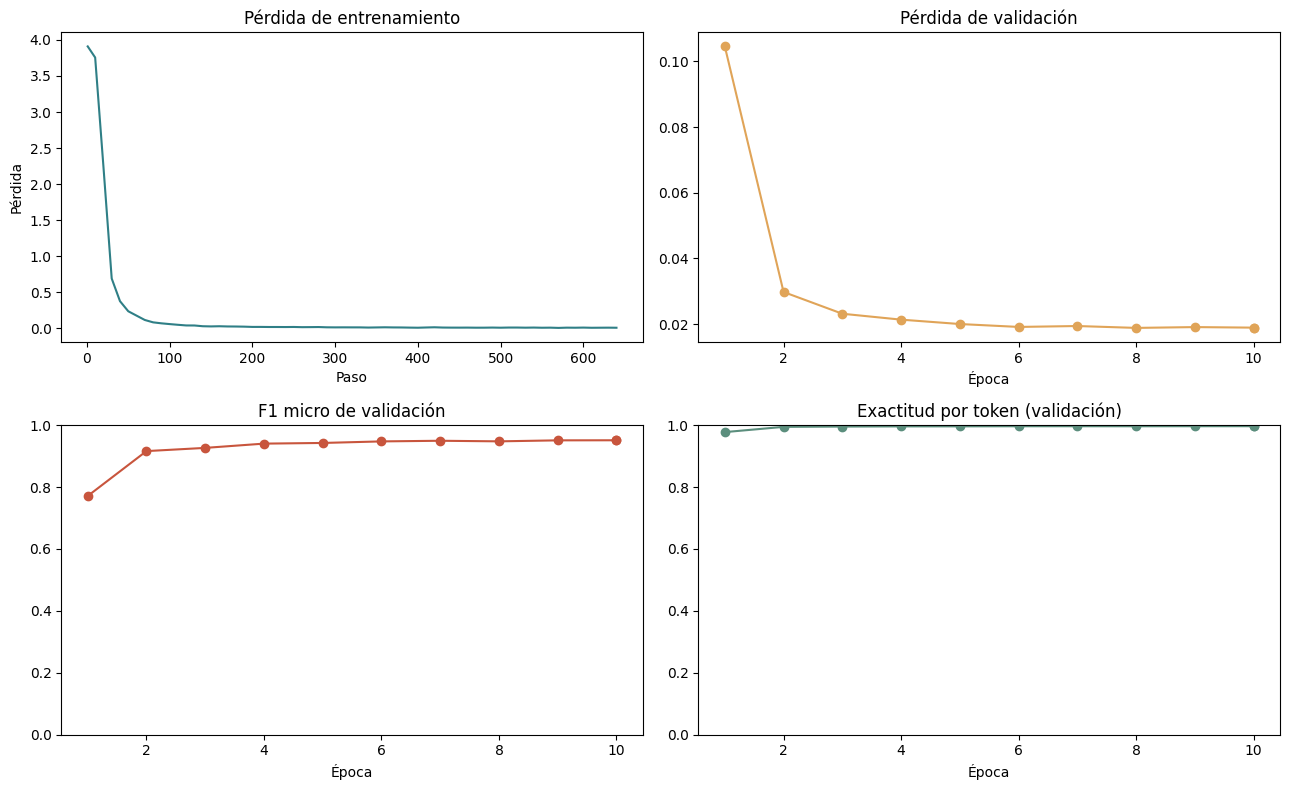

In [20]:

entrenador.train()

print("\nResultados en validación:")
for clave, valor in entrenador.evaluate(val_ds).items():
    if isinstance(valor, float) and not clave.endswith("runtime"):
        print(f"  {clave}: {valor:.4f}")

# Guardamos pesos, tokenizador y el mapa de etiquetas para poder recargar el
# modelo sin volver a entrenar.
entrenador.save_model(SALIDA)
tokenizer.save_pretrained(SALIDA)
(SALIDA / "labels.json").write_text(
    json.dumps({
        "labels": etiquetas,
        "label2id": label2id,
        "id2label": {str(k): v for k, v in id2label.items()},
        "modelo": MODELO,
        "max_len": MAX_LEN,
        "stride": STRIDE,
        "seed": SEED,
    }, ensure_ascii=False, indent=2),
    encoding="utf-8",
)
print("Modelo guardado en", SALIDA)

# El historial guarda una entrada por paso (pérdida) y una por época
# (pérdida de validación, F1 y exactitud).
historial = entrenador.state.log_history
pasos = [h["step"] for h in historial if "loss" in h]
perdida = [h["loss"] for h in historial if "loss" in h]
epocas = [h["epoch"] for h in historial if "eval_loss" in h]
perdida_val = [h["eval_loss"] for h in historial if "eval_loss" in h]
f1_val = [h["eval_f1"] for h in historial if "eval_f1" in h]
acc_val = [h["eval_accuracy"] for h in historial if "eval_accuracy" in h]

fig, ejes = plt.subplots(2, 2, figsize=(13, 8))

ejes[0, 0].plot(pasos, perdida, color="#2F7F86")
ejes[0, 0].set_title("Pérdida de entrenamiento")
ejes[0, 0].set_xlabel("Paso")
ejes[0, 0].set_ylabel("Pérdida")

ejes[0, 1].plot(epocas, perdida_val, marker="o", color="#E0A458")
ejes[0, 1].set_title("Pérdida de validación")
ejes[0, 1].set_xlabel("Época")

ejes[1, 0].plot(epocas, f1_val, marker="o", color="#C8553D")
ejes[1, 0].set_title("F1 micro de validación")
ejes[1, 0].set_xlabel("Época")
ejes[1, 0].set_ylim(0, 1)

ejes[1, 1].plot(epocas, acc_val, marker="o", color="#5B8E7D")
ejes[1, 1].set_title("Exactitud por token (validación)")
ejes[1, 1].set_xlabel("Época")
ejes[1, 1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

## Caja 6 · Evaluar por documento

**Entra:** el modelo entrenado y el conjunto de prueba.
**Sale:** métricas estrictas y relajadas por tipo, confusiones y comparación de métodos.
**Herramienta:** spans de carácter y emparejamiento por solapamiento.

La evaluación por ventana cuenta dos veces las entidades que caen en el solape. Para que la
cifra sea comparable con el corpus, reconstruimos los spans de carácter de cada documento,
eliminamos duplicados y comparamos contra las anotaciones oficiales. La métrica estricta exige
los mismos límites; la relajada acepta un solapamiento del 50 %.

In [21]:
# Texto por documento: lo usamos para recortar y reconstruir entidades.
textos = {r["id"]: r["text"] for r in registros}

def spans_de_etiquetas(offsets, tags):
    """Reconstruye entidades a partir de la secuencia B-/I-/O."""
    spans, actual = [], None
    for (ini, fin), t in zip(offsets, tags):
        etiqueta = id2label[int(t)] if t != -100 else "O"
        if etiqueta == "O":
            if actual:
                spans.append(actual)
                actual = None
            continue

        prefijo, tipo = etiqueta.split("-", 1)
        if prefijo == "B" or actual is None or actual["type"] != tipo:
            if actual:
                spans.append(actual)
            actual = {"start": ini, "end": fin, "type": tipo}
        else:
            actual["end"] = fin

    if actual:
        spans.append(actual)
    return spans


def recortar(span, texto):
    """Quita espacios y puntuación en los bordes del span.

    El tokenizador puede incluir el punto final en una predicción; al
    reemplazar no queremos borrar ese punto.
    """
    ini, fin = span["start"], span["end"]
    while ini < fin and texto[ini] in " \t\n.,;:)]}\"'":
        ini += 1
    while fin > ini and texto[fin - 1] in " \t\n.,;:([{\"'":
        fin -= 1
    return {"start": ini, "end": fin, "type": span["type"]}


def solapan(a, b):
    """Número de caracteres que comparten dos spans."""
    return max(0, min(a["end"], b["end"]) - max(a["start"], b["start"]))


def deduplicar(spans):
    """Elimina la misma entidad repetida en ventanas solapadas."""
    ordenados = sorted(spans, key=lambda s: (s["start"], -(s["end"] - s["start"])))
    limpios = []
    for span in ordenados:
        repetido = any(
            span["type"] == c["type"]
            and solapan(span, c) >= 0.5 * min(span["end"] - span["start"], c["end"] - c["start"])
            for c in limpios
        )
        if not repetido:
            limpios.append(span)
    return limpios


def sin_solapes(spans):
    """Conserva el span más largo cuando dos predicciones se cruzan."""
    ordenados = sorted(spans, key=lambda s: (-(s["end"] - s["start"]), s["start"]))
    limpios = []
    for span in ordenados:
        if not any(solapan(span, c) > 0 for c in limpios):
            limpios.append(span)
    return limpios


# El sexo aparece como H, M, F, Varón, Mujer, Niño, etc. Normalizamos esa
# lista para no descartar formas válidas del corpus.
SEXO_VALIDOS = {
    "h", "m", "f", "v", "varón", "varon", "mujer", "hombre",
    "niño", "niña", "nino", "nina", "masculino", "femenino",
    "masculina", "femenina", "anciano", "anciana", "hembra",
    "recién nacido", "recien nacido", "recién nacida", "recien nacida",
}
SEXO_VALIDOS = {re.sub(r"\s+", "", x) for x in SEXO_VALIDOS}
MESES = r"(enero|febrero|marzo|abril|mayo|junio|julio|agosto|septiembre|setiembre|octubre|noviembre|diciembre)"


def validar_span(span, texto):
    """Descarta fragmentos que claramente no son del tipo predicho.

    El filtro es deliberadamente permisivo: en el corpus hay edades como
    "18 meses", fechas como "año 2004" y sexos como "Varón". Solo eliminamos
    basura como "/", "a" o números sueltos que rompen el texto al reemplazar.
    """
    frag = texto[span["start"]:span["end"]].strip()
    low = frag.lower()
    tipo = span["type"]

    if not frag:
        return False
    letras = sum(c.isalpha() for c in frag)
    digitos = sum(c.isdigit() for c in frag)

    if tipo == "SEXO_SUJETO_ASISTENCIA":
        return re.sub(r"\s+", "", low.strip(".")) in SEXO_VALIDOS
    if tipo == "EDAD_SUJETO_ASISTENCIA":
        if digitos >= 1:
            return True
        if any(w in low for w in ("año", "mes", "día", "dia", "semana")):
            return True
        return low in {"adolescente", "recién nacido", "recien nacido",
                       "recién nacida", "recien nacida", "lactante"}
    if tipo == "FECHAS":
        if re.search(MESES, low):
            return True
        if digitos < 4:
            return False
        if any(c in frag for c in "/-."):
            return True
        return bool(re.fullmatch(r"\d{4}", frag)) or "año" in low
    if tipo.startswith("ID_"):
        return digitos >= 2 or letras >= 4
    if tipo == "CORREO_ELECTRONICO":
        return len(frag) >= 4 and (letras >= 2 or "@" in frag)
    if tipo in {"NUMERO_TELEFONO", "NUMERO_FAX"}:
        return digitos >= 6
    if tipo == "TERRITORIO":
        return len(frag) >= 2 and (letras >= 2 or digitos >= 2)
    if tipo == "CALLE":
        return len(frag) >= 2 and (letras >= 1 or digitos >= 2)
    if tipo == "PROFESION":
        return letras >= 3
    return len(frag) >= 2 and letras >= 1

In [22]:
# Predecimos todas las ventanas de prueba de una sola pasada.
prediccion = entrenador.predict(test_ds)
pred_ids = np.argmax(prediccion.predictions, axis=-1)

pred_por_doc = defaultdict(list)
for i in range(len(test_ds)):
    offsets = test_ds[i]["offsets"]
    doc = test_ds[i]["doc_id"]
    # La predicción viene con padding; cortamos al largo real de la ventana.
    tags = pred_ids[i][:len(offsets)]

    for span in spans_de_etiquetas(offsets, tags):
        span = recortar(span, textos[doc])
        if span["end"] > span["start"] and validar_span(span, textos[doc]):
            pred_por_doc[doc].append(span)

# Las ventanas solapadas pueden predecir la misma entidad dos veces.
for doc in pred_por_doc:
    pred_por_doc[doc] = deduplicar(pred_por_doc[doc])

docs_eval = list(dict.fromkeys(test_ds["doc_id"]))
gold_todos = {r["id"]: r["entities"] for r in registros}
gold_por_doc = {doc: gold_todos[doc] for doc in docs_eval}

print("Documentos evaluados:", len(docs_eval))
print("Entidades reales:", sum(len(v) for v in gold_por_doc.values()))
print("Entidades predichas:", sum(len(v) for v in pred_por_doc.values()))

Documentos evaluados: 250
Entidades reales: 5661
Entidades predichas: 5708


In [23]:
def evaluar(gold, pred, estricto=True):
    """Empareja entidades reales y predichas y acumula TP, FP y FN.

    En modo estricto exige los mismos límites de carácter. En modo relajado
    acepta que el solapamiento sea al menos el 50 % de la unión.
    """
    stats = {t: {"tp": 0, "fp": 0, "fn": 0} for t in tipos}

    for doc, reales in gold.items():
        predichas = pred.get(doc, [])
        usadas = set()

        for g in reales:
            elegida = None
            for i, p in enumerate(predichas):
                if i in usadas or p["type"] != g["type"]:
                    continue
                if estricto:
                    coincide = p["start"] == g["start"] and p["end"] == g["end"]
                else:
                    inter = solapan(p, g)
                    union = max(p["end"], g["end"]) - min(p["start"], g["start"])
                    coincide = union > 0 and inter / union >= 0.5
                if coincide:
                    elegida = i
                    break

            if elegida is None:
                stats[g["type"]]["fn"] += 1
            else:
                usadas.add(elegida)
                stats[g["type"]]["tp"] += 1

        # Las predicciones que no se emparejaron con ninguna entidad real son FP.
        for i, p in enumerate(predichas):
            if i not in usadas:
                stats[p["type"]]["fp"] += 1

    return stats


def resumen(stats):
    """Calcula precisión, recall y F1 micro y macro a partir de TP/FP/FN."""
    tp = sum(s["tp"] for s in stats.values())
    fp = sum(s["fp"] for s in stats.values())
    fn = sum(s["fn"] for s in stats.values())

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0

    f1s = []
    for s in stats.values():
        p = s["tp"] / (s["tp"] + s["fp"]) if s["tp"] + s["fp"] else 0.0
        r = s["tp"] / (s["tp"] + s["fn"]) if s["tp"] + s["fn"] else 0.0
        if s["tp"] + s["fn"] > 0:
            f1s.append(2 * p * r / (p + r) if p + r else 0.0)

    return {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "f1_macro": float(np.mean(f1s)) if f1s else 0.0,
        "tp": tp,
        "fp": fp,
        "fn": fn,
    }

stats_estricto = evaluar(gold_por_doc, pred_por_doc, estricto=True)
stats_relajado = evaluar(gold_por_doc, pred_por_doc, estricto=False)

print("BETO estricto:", {k: round(v, 3) for k, v in resumen(stats_estricto).items()})
print("BETO relajado:", {k: round(v, 3) for k, v in resumen(stats_relajado).items()})

BETO estricto: {'precision': 0.955, 'recall': 0.963, 'f1': 0.959, 'f1_macro': 0.747, 'tp': 5450, 'fp': 258, 'fn': 211}
BETO relajado: {'precision': 0.969, 'recall': 0.977, 'f1': 0.973, 'f1_macro': 0.85, 'tp': 5530, 'fp': 178, 'fn': 131}


,tipo,precision,recall,f1,soporte
0,TERRITORIO,0.968,0.975,0.971,956
1,FECHAS,0.995,0.989,0.992,611
2,EDAD_SUJETO_ASISTENCIA,0.970,0.990,0.980,518
3,NOMBRE_SUJETO_ASISTENCIA,0.998,0.996,0.997,502
4,NOMBRE_PERSONAL_SANITARIO,0.982,0.990,0.986,501
5,SEXO_SUJETO_ASISTENCIA,0.993,0.985,0.989,461
6,CALLE,0.909,0.942,0.925,413
7,PAIS,0.956,0.959,0.957,363
8,ID_SUJETO_ASISTENCIA,0.975,0.965,0.970,283
9,CORREO_ELECTRONICO,0.980,0.988,0.984,249


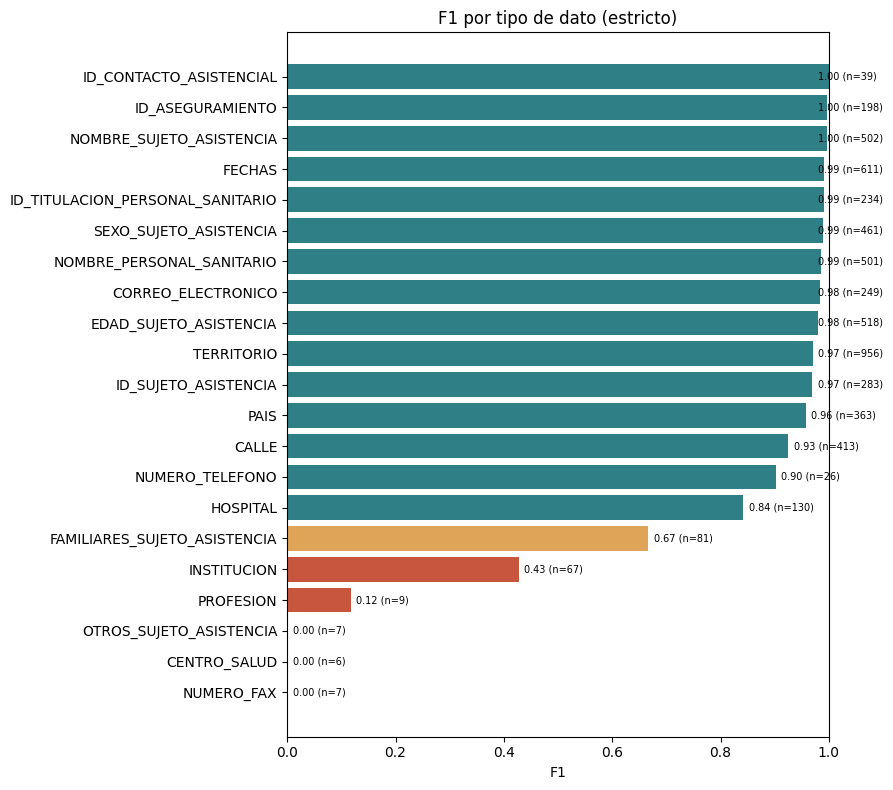

In [24]:
filas = []
for tipo, s in stats_estricto.items():
    p = s["tp"] / (s["tp"] + s["fp"]) if s["tp"] + s["fp"] else 0.0
    r = s["tp"] / (s["tp"] + s["fn"]) if s["tp"] + s["fn"] else 0.0
    f = 2 * p * r / (p + r) if p + r else 0.0
    filas.append({
        "tipo": tipo,
        "precision": p,
        "recall": r,
        "f1": f,
        "soporte": s["tp"] + s["fn"],
    })

tabla_tipos = pd.DataFrame(filas).sort_values("soporte", ascending=False)
display(tabla_tipos.round(3).reset_index(drop=True))

# Gráfica de F1 por tipo: rojo si es bajo, naranja si es medio y verde si es alto.
orden = tabla_tipos[tabla_tipos["soporte"] > 0].sort_values("f1")
fig, ax = plt.subplots(figsize=(9, 8))
colores = ["#C8553D" if f < 0.5 else "#E0A458" if f < 0.8 else "#2F7F86" for f in orden["f1"]]
ax.barh(orden["tipo"], orden["f1"], color=colores)
ax.set_xlim(0, 1)
ax.set_xlabel("F1")
ax.set_title("F1 por tipo de dato (estricto)")
for i, (f, n) in enumerate(zip(orden["f1"], orden["soporte"])):
    ax.text(min(f + 0.01, 0.98), i, f"{f:.2f} (n={n})", va="center", fontsize=7)
plt.tight_layout()
plt.show()

Confusiones más frecuentes:
  FALSO POSITIVO                         -> TERRITORIO                             19
  FALSO POSITIVO                         -> CALLE                                  17
  FALSO POSITIVO                         -> INSTITUCION                            17
  FALSO POSITIVO                         -> FAMILIARES_SUJETO_ASISTENCIA           17
  FALSO POSITIVO                         -> EDAD_SUJETO_ASISTENCIA                 13
  INSTITUCION                            -> NO DETECTADO                           12
  PAIS                                   -> NO DETECTADO                           10
  FALSO POSITIVO                         -> HOSPITAL                               9
  FALSO POSITIVO                         -> PAIS                                   7
  SEXO_SUJETO_ASISTENCIA                 -> NO DETECTADO                           6
  FAMILIARES_SUJETO_ASISTENCIA           -> NO DETECTADO                           6
  ID_SUJETO_ASISTENCIA        

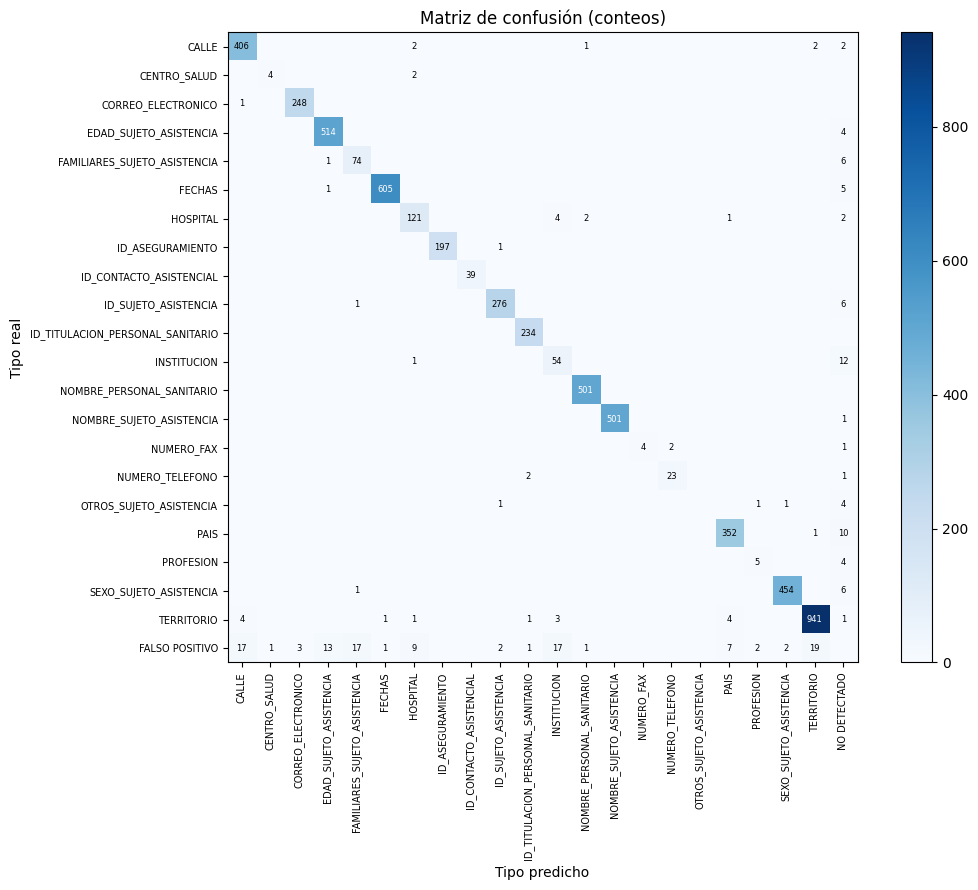


Predicciones guardadas en predicciones_test.csv


In [25]:
# ---------------------------------------------------------------------------
# Matriz de confusión completa
# Cada entidad real se empareja con la predicción que más la solapa. La
# diagonal muestra los aciertos; fuera de la diagonal quedan las confusiones.
# ---------------------------------------------------------------------------
matriz_conf = Counter()

for doc, reales in gold_por_doc.items():
    predichas = pred_por_doc.get(doc, [])
    usadas = set()

    for g in reales:
        mejor, mejor_solape = None, 0
        for i, p in enumerate(predichas):
            if i in usadas:
                continue
            ov = solapan(g, p)
            if ov > mejor_solape:
                mejor_solape, mejor = ov, i

        if mejor is None:
            matriz_conf[(g["type"], "NO DETECTADO")] += 1
        else:
            usadas.add(mejor)
            matriz_conf[(g["type"], predichas[mejor]["type"])] += 1

    for i, p in enumerate(predichas):
        if i not in usadas:
            matriz_conf[("FALSO POSITIVO", p["type"])] += 1

# Imprimimos solo los errores, es decir, donde el tipo real y el predicho difieren.
errores = Counter({k: v for k, v in matriz_conf.items() if k[0] != k[1]})
print("Confusiones más frecuentes:")
for (real, predicha), n in errores.most_common(15):
    print(f"  {real:<38} -> {predicha:<38} {n}")

# Tipos que aparecen en la matriz, conservando el orden alfabético del corpus.
usados = set()
for real, predicha in matriz_conf:
    if real != "FALSO POSITIVO":
        usados.add(real)
    if predicha != "NO DETECTADO":
        usados.add(predicha)

tipos_matriz = [t for t in tipos if t in usados]
filas_matriz = tipos_matriz + ["FALSO POSITIVO"]
columnas_matriz = tipos_matriz + ["NO DETECTADO"]

matriz = np.zeros((len(filas_matriz), len(columnas_matriz)), dtype=int)
for i, real in enumerate(filas_matriz):
    for j, predicha in enumerate(columnas_matriz):
        matriz[i, j] = matriz_conf.get((real, predicha), 0)

fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(matriz, cmap="Blues")
ax.set_xticks(range(len(columnas_matriz)))
ax.set_xticklabels(columnas_matriz, rotation=90, fontsize=7)
ax.set_yticks(range(len(filas_matriz)))
ax.set_yticklabels(filas_matriz, fontsize=7)
ax.set_xlabel("Tipo predicho")
ax.set_ylabel("Tipo real")
ax.set_title("Matriz de confusión (conteos)")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

for i in range(matriz.shape[0]):
    for j in range(matriz.shape[1]):
        if matriz[i, j] > 0:
            ax.text(j, i, matriz[i, j], ha="center", va="center", fontsize=6,
                    color="white" if matriz[i, j] > matriz.max() * 0.5 else "black")

plt.tight_layout()
plt.show()

# Guardamos las predicciones para revisarlas fuera del notebook.
pd.DataFrame([
    {"documento": doc, "inicio": s["start"], "fin": s["end"], "tipo": s["type"]}
    for doc, spans in pred_por_doc.items() for s in spans
]).to_csv(BASE / "predicciones_test.csv", index=False)
print("\nPredicciones guardadas en predicciones_test.csv")

,precision,recall,f1,f1_macro
Reglas,0.969,0.419,0.585,0.360
BETO,0.955,0.963,0.959,0.747
Unión,0.946,0.963,0.954,0.745


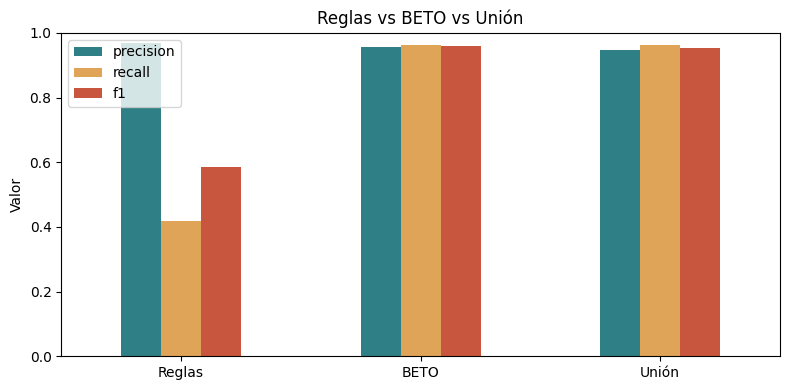

Training Loss,Validation Loss,Epoch,F1,Precision,Recall,F1 Macro,Accuracy
0.006198,0.019781,10,0.952708,0.944359,0.961205,0.742045,0.996361


Ventana: F1=0.9527 | macro=0.7420
Documento: F1=0.9587 | macro=0.7475


In [26]:
# ---------------------------------------------------------------------------
# Comparación de los tres métodos sobre el mismo conjunto de prueba
# ---------------------------------------------------------------------------
regex_por_doc = {}
for doc in gold_por_doc:
    spans = [recortar(s, textos[doc]) for s in spans_regex(textos[doc])]
    regex_por_doc[doc] = deduplicar([
        s for s in spans if s["end"] > s["start"] and validar_span(s, textos[doc])
    ])

# La unión agrega las reglas que BETO no detectó, sin duplicar las que ya están.
union_por_doc = {}
for doc in gold_por_doc:
    union = list(pred_por_doc.get(doc, []))
    for span in regex_por_doc.get(doc, []):
        if not any(solapan(span, p) > 0 for p in union):
            union.append(span)
    union_por_doc[doc] = union

comparacion = {}
for nombre, pred in (("Reglas", regex_por_doc), ("BETO", pred_por_doc), ("Unión", union_por_doc)):
    comparacion[nombre] = resumen(evaluar(gold_por_doc, pred, estricto=True))

tabla_comparacion = pd.DataFrame(comparacion).T[["precision", "recall", "f1", "f1_macro"]]
display(tabla_comparacion.round(3))

# Gráfica comparativa de precisión, recall y F1.
tabla_comparacion[["precision", "recall", "f1"]].plot.bar(
    figsize=(8, 4), color=["#2F7F86", "#E0A458", "#C8553D"]
)
plt.ylim(0, 1)
plt.title("Reglas vs BETO vs Unión")
plt.ylabel("Valor")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Comparamos también la métrica por ventana con la métrica por documento.
por_ventana = entrenador.evaluate(test_ds)
print(f"Ventana: F1={por_ventana['eval_f1']:.4f} | macro={por_ventana['eval_f1_macro']:.4f}")
print(f"Documento: F1={comparacion['BETO']['f1']:.4f} | macro={comparacion['BETO']['f1_macro']:.4f}")

## Caja 7 · Instanciar: anonimizar y medir fuga

**Entra:** un texto clínico nuevo.
**Sale:** el mismo texto con los datos personales reemplazados y el reporte de fuga.
**Herramienta:** el modelo entrenado y un mapa de 22 tipos a 6 etiquetas legibles.

Para que el resultado se lea bien agrupamos los 22 tipos en seis reemplazos: `[NOMBRE]`,
`[IDENTIFICACIÓN]`, `[CONTACTO]`, `[LUGAR]`, `[FECHA]` y `[OTRO]`. La sustitución se hace con
las posiciones de carácter, de derecha a izquierda, para no mover los offsets. La fuga mide qué
porcentaje de las entidades reales sigue visible después de anonimizar.

> En `MODO_RAPIDO` el modelo se entrena con muy pocos documentos y sirve solo para comprobar
> que el flujo funciona; las predicciones de la demostración no son representativas.

In [27]:
# ---------------------------------------------------------------------------
# Agrupación de los 22 tipos en seis etiquetas legibles
# ---------------------------------------------------------------------------
GRUPOS = {
    "NOMBRE_SUJETO_ASISTENCIA": "NOMBRE",
    "NOMBRE_PERSONAL_SANITARIO": "NOMBRE",
    "FAMILIARES_SUJETO_ASISTENCIA": "NOMBRE",
    "ID_SUJETO_ASISTENCIA": "IDENTIFICACIÓN",
    "ID_ASEGURAMIENTO": "IDENTIFICACIÓN",
    "ID_TITULACION_PERSONAL_SANITARIO": "IDENTIFICACIÓN",
    "ID_CONTACTO_ASISTENCIAL": "IDENTIFICACIÓN",
    "ID_EMPLEO_PERSONAL_SANITARIO": "IDENTIFICACIÓN",
    "CORREO_ELECTRONICO": "CONTACTO",
    "NUMERO_TELEFONO": "CONTACTO",
    "NUMERO_FAX": "CONTACTO",
    "CALLE": "LUGAR",
    "TERRITORIO": "LUGAR",
    "PAIS": "LUGAR",
    "HOSPITAL": "LUGAR",
    "CENTRO_SALUD": "LUGAR",
    "INSTITUCION": "LUGAR",
    "FECHAS": "FECHA",
    "EDAD_SUJETO_ASISTENCIA": "OTRO",
    "SEXO_SUJETO_ASISTENCIA": "OTRO",
    "PROFESION": "OTRO",
    "OTROS_SUJETO_ASISTENCIA": "OTRO",
}


def predecir_documento(texto):
    """Devuelve las entidades detectadas en un texto nuevo, sin duplicados."""
    cod = tokenizer(
        texto,
        max_length=MAX_LEN,
        stride=STRIDE,
        truncation=True,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        add_special_tokens=True,
    )

    spans = []
    modelo.eval()
    with torch.no_grad():
        for i in range(len(cod["input_ids"])):
            lote = {
                "input_ids": torch.tensor([cod["input_ids"][i]]).to(DISPOSITIVO),
                "attention_mask": torch.tensor([cod["attention_mask"][i]]).to(DISPOSITIVO),
            }
            tags = modelo(**lote).logits[0].argmax(-1).cpu().numpy()
            for span in spans_de_etiquetas(cod["offset_mapping"][i], tags):
                span = recortar(span, texto)
                if span["end"] > span["start"] and validar_span(span, texto):
                    spans.append(span)

    return sin_solapes(deduplicar(spans))


def anonimizar(texto):
    """Reemplaza cada entidad por su etiqueta y devuelve el reporte.

    Recorremos los spans de derecha a izquierda para que los reemplazos no
    muevan las posiciones de los que faltan.
    """
    spans = predecir_documento(texto)
    salida = texto
    for span in sorted(spans, key=lambda s: s["start"], reverse=True):
        grupo = GRUPOS.get(span["type"], "OTRO")
        salida = salida[:span["start"]] + f"[{grupo}]" + salida[span["end"]:]
    return salida, spans


def medir_fuga(texto_anonimizado, entidades_reales):
    """Cuenta cuántas entidades reales siguen visibles en el texto anonimizado."""
    visibles = [
        e for e in entidades_reales
        if e["text"].strip() and e["text"] in texto_anonimizado
    ]
    return len(visibles), len(entidades_reales)

Probamos con un documento del conjunto de prueba. Mostramos un extracto del original, las
entidades detectadas y el resultado. Al final se reporta la fuga sobre las entidades reales
de ese documento.

In [28]:
# Tomamos el primer documento de prueba y mostramos el antes y el después.
demo = next(r for r in registros if r["split"] == "prueba")
texto_anon, spans_demo = anonimizar(demo["text"])

print("DOCUMENTO ORIGINAL (extracto)")
print(demo["text"][:1200])

print("\nENTIDADES DETECTADAS")
display(pd.DataFrame([
    {"tipo": s["type"], "texto": demo["text"][s["start"]:s["end"]]}
    for s in spans_demo
]).head(20))

print("\nDOCUMENTO ANONIMIZADO (extracto)")
print(texto_anon[:1200])

fuga, total = medir_fuga(texto_anon, demo["entities"])
if total:
    print(f"\nFuga: {fuga}/{total} entidades ({100 * fuga / total:.1f}%)")
else:
    print("\nFuga: el documento no tiene entidades para comparar.")

DOCUMENTO ORIGINAL (extracto)
Datos del paciente.
Nombre:  Ignacio.
Apellidos: Rico Pedroza.
NHC: 5467980.
Domicilio: Av. Beniarda, 13.
Localidad/ Provincia: Valencia.
CP: 46271.
Datos asistenciales.
Fecha de nacimiento: 11/02/1970.
País: España.
Edad: 46 años Sexo: H.
Fecha de Ingreso: 28/05/2016.
Médico:  Ignacio Rubio Tortosa Servicio  NºCol: 46 28 52938.
Informe clínico del paciente: Paciente de 46 años que consultó por dolor a nivel de hipogastrio, eyaculación dolorosa, hemospermia y sensación de peso a nivel testicular atribuido hasta entonces a varicocele derecho ya conocido desde hacía un año. Entre sus antecedentes personales destacaba un episodio de prostatitis aguda un año antes de la consulta.
A la exploración física el paciente presentaba buen estado general, varicocele derecho y no se palpaban masas a nivel de ambos testículos. El tacto rectal mostraba una próstata irregular, ligeramente aumentada de tamaño con zonas induradas y algo dolorosa a la exploración.
Se solicitó

,tipo,texto
0,CALLE,"Avda. Gaspar Aguilar, 90"
1,CORREO_ELECTRONICO,nachorutor@hotmail.com
2,NOMBRE_PERSONAL_SANITARIO,Ignacio Rubio Tortosa
3,NOMBRE_PERSONAL_SANITARIO,Ignacio Rubio Tortosa
4,HOSPITAL,Hospital Dr. Peset
5,CALLE,"Av. Beniarda, 13"
6,NOMBRE_SUJETO_ASISTENCIA,Rico Pedroza
7,ID_TITULACION_PERSONAL_SANITARIO,46 28 52938
8,FECHAS,11/02/1970
9,FECHAS,28/05/2016



DOCUMENTO ANONIMIZADO (extracto)
Datos del paciente.
Nombre:  [NOMBRE].
Apellidos: [NOMBRE].
NHC: [IDENTIFICACIÓN].
Domicilio: [LUGAR].
Localidad/ Provincia: [LUGAR].
CP: [LUGAR].
Datos asistenciales.
Fecha de nacimiento: [FECHA].
País: [LUGAR].
Edad: [OTRO] Sexo: [OTRO].
Fecha de Ingreso: [FECHA].
Médico:  [NOMBRE] Servicio  NºCol: [IDENTIFICACIÓN].
Informe clínico del paciente: Paciente de [OTRO] que consultó por dolor a nivel de hipogastrio, eyaculación dolorosa, hemospermia y sensación de peso a nivel testicular atribuido hasta entonces a varicocele derecho ya conocido desde hacía un año. Entre sus antecedentes personales destacaba un episodio de prostatitis aguda un año antes de la consulta.
A la exploración física el paciente presentaba buen estado general, varicocele derecho y no se palpaban masas a nivel de ambos testículos. El tacto rectal mostraba una próstata irregular, ligeramente aumentada de tamaño con zonas induradas y algo dolorosa a la exploración.
Se solicitó ecograf

### Recargar el modelo guardado

Esta comprobación confirma que el modelo quedó bien guardado y se puede usar sin volver a
entrenar.

In [29]:
# Recargamos el modelo desde disco para comprobar que el guardado quedó bien.
from transformers import AutoModelForTokenClassification, AutoTokenizer

modelo = AutoModelForTokenClassification.from_pretrained(SALIDA).to(DISPOSITIVO)
tokenizer = AutoTokenizer.from_pretrained(SALIDA)
print("Modelo recargado desde", SALIDA)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Modelo recargado desde /content/models/beto-meddocan


### Texto libre

El corpus es de España; este texto usa un formato colombiano y sirve como prueba de estrés.
Si el modelo no reconoce algún dato, queda visible en el resultado y se puede revisar a mano.

In [30]:
# Texto de prueba con formato colombiano. No viene del corpus, así que sirve
# para ver cómo se comporta el modelo con datos nuevos.
TEXTO = """Paciente: María Fernanda López. Documento: 1024567890.
Correo: mflopez@example.com. Teléfono: 300 123 4567.
Fecha de ingreso: 12/03/2024. Edad: 45 años. Sexo: F.
Dirección: Calle 45 # 12-30, Bogotá."""

anonimizado, detectadas = anonimizar(TEXTO)
print(anonimizado)
display(pd.DataFrame([
    {"tipo": s["type"], "texto": TEXTO[s["start"]:s["end"]]}
    for s in detectadas
]))

Paciente: [NOMBRE]. Documento: [IDENTIFICACIÓN].
Correo: [CONTACTO]. Teléfono: [CONTACTO].
Fecha de ingreso: [FECHA]. Edad: [OTRO]. Sexo: [OTRO].
Dirección: [LUGAR], [LUGAR].


,tipo,texto
0,NOMBRE_PERSONAL_SANITARIO,María Fernanda López
1,CORREO_ELECTRONICO,mflopez@example.com
2,CALLE,Calle 45 # 12-30
3,NUMERO_TELEFONO,300 123 4567
4,ID_TITULACION_PERSONAL_SANITARIO,1024567890
5,FECHAS,12/03/2024
6,EDAD_SUJETO_ASISTENCIA,45 años
7,TERRITORIO,Bogotá
8,SEXO_SUJETO_ASISTENCIA,F


## Caja 8 · Adaptar el modelo a Colombia

**Entra:** el modelo entrenado con MEDDOCAN (España) y el corpus original.
**Sale:** un modelo adaptado a formatos colombianos y una medición de cuánto mejora.
**Herramienta:** datos sintéticos colombianos, aumento de datos, reglas locales y BETO.

MEDDOCAN está escrito con historias clínicas de España. En Colombia los datos personales tienen
otra forma: cédula en lugar de DNI, direcciones tipo `Cra. 72 # 40B-15`, celulares `3XX`, EPS,
barrios y municipios. Además, las historias reales no siempre traen rótulos como `Nombre:` o
`NHC:`; muchas veces los datos aparecen dentro del relato.

Esta caja responde una pregunta concreta: **¿cuántos datos personales se le escapan al modelo
cuando lo usamos con historias colombianas, y cuánto se reduce esa fuga si lo adaptamos?**

| Paso | Qué hace |
|---|---|
| 8.1 | Construye un conjunto de prueba colombiano sintético y anotado |
| 8.2 | Mide el modelo de España sobre ese conjunto |
| 8.3 | Agrega reglas para formatos colombianos (cédula, celular, dirección, registro médico) |
| 8.4 | Crea copias colombianas del corpus de entrenamiento (aumento de datos) |
| 8.5 | Reajusta BETO con el corpus original + las copias colombianas |
| 8.6 | Compara los cuatro sistemas en España y en Colombia |
| 8.7 | Demostración con una nota clínica colombiana |

> Todos los datos de esta caja son **sintéticos**: los nombres, documentos, teléfonos y
> direcciones se combinan al azar y no corresponden a personas reales.

In [31]:
# ---------------------------------------------------------------------------
# Valores colombianos para generar datos sintéticos
# Ningún valor corresponde a una persona real: nombres y apellidos se combinan
# al azar, y documentos, teléfonos y direcciones se generan con números aleatorios.
# ---------------------------------------------------------------------------
import unicodedata

NOMBRES_F = [
    "María Fernanda", "Luisa", "Diana Marcela", "Paola", "Andrea", "Natalia", "Camila",
    "Valentina", "Daniela", "Laura", "Sandra Milena", "Yolanda", "Luz Marina", "Gloria",
    "Martha Lucía", "Claudia Patricia", "Angie", "Yeimy", "Leidy Johana", "Ana María",
    "Carolina", "Juliana", "Marcela", "Adriana", "Lina", "Viviana", "Nubia", "Rosalba",
    "Mónica", "Jenny", "Sara", "Isabela", "Ximena", "Dora Inés", "Blanca Cecilia",
]
NOMBRES_M = [
    "Juan Camilo", "Andrés Felipe", "Carlos Arturo", "Jhon Fredy", "Luis Alberto",
    "José Gregorio", "Sebastián", "Santiago", "Mateo", "Julián", "Jorge Eliécer", "Fabián",
    "Hernán", "Wilson", "Édgar", "Nelson", "Brayan", "Duván", "Yesid", "Cristian",
    "Alejandro", "Diego", "Mauricio", "Germán", "Álvaro", "Ricardo", "Camilo", "Esteban",
    "Fredy", "Miguel Ángel", "Jairo", "Orlando", "Rubén Darío", "Kevin", "Samuel",
]
APELLIDOS = [
    "Rodríguez", "Gómez", "González", "Martínez", "García", "López", "Hernández", "Sánchez",
    "Ramírez", "Pérez", "Díaz", "Muñoz", "Rojas", "Moreno", "Jiménez", "Vargas", "Castro",
    "Ortiz", "Rincón", "Cárdenas", "Quintero", "Cuervo", "Osorio", "Restrepo", "Zapata",
    "Agudelo", "Arango", "Bermúdez", "Cifuentes", "Montoya", "Patiño", "Valencia", "Ospina",
    "Salazar", "Herrera", "Mosquera", "Palacios", "Chaparro", "Barrera", "Suárez",
    "Benavides", "Bonilla", "Caicedo", "Londoño", "Mejía", "Nieto", "Parra", "Pineda",
    "Rueda", "Torres", "Guerrero", "Becerra", "Carvajal", "Duarte", "Fajardo", "Galindo",
]
# (ciudad o municipio, departamento)
CIUDADES = [
    ("Bogotá", "Cundinamarca"), ("Medellín", "Antioquia"), ("Cali", "Valle del Cauca"),
    ("Barranquilla", "Atlántico"), ("Cartagena", "Bolívar"), ("Bucaramanga", "Santander"),
    ("Pereira", "Risaralda"), ("Manizales", "Caldas"), ("Ibagué", "Tolima"),
    ("Neiva", "Huila"), ("Villavicencio", "Meta"), ("Tunja", "Boyacá"), ("Pasto", "Nariño"),
    ("Montería", "Córdoba"), ("Santa Marta", "Magdalena"), ("Valledupar", "Cesar"),
    ("Popayán", "Cauca"), ("Armenia", "Quindío"), ("Sincelejo", "Sucre"),
    ("Riohacha", "La Guajira"), ("Soacha", "Cundinamarca"), ("Bello", "Antioquia"),
    ("Envigado", "Antioquia"), ("Palmira", "Valle del Cauca"), ("Floridablanca", "Santander"),
    ("Girardot", "Cundinamarca"), ("Pitalito", "Huila"), ("Yopal", "Casanare"),
    ("Quibdó", "Chocó"), ("Facatativá", "Cundinamarca"), ("Duitama", "Boyacá"),
    ("Sogamoso", "Boyacá"), ("Tuluá", "Valle del Cauca"), ("Rionegro", "Antioquia"),
]
BARRIOS = [
    "Patio Bonito", "Kennedy Central", "Bosa La Libertad", "Suba Rincón", "Engativá Centro",
    "Chapinero Alto", "Las Cruces", "San Cristóbal Sur", "Lucero Alto", "Usme Centro",
    "El Poblado", "Manrique", "Belén", "Robledo", "Aranjuez", "Siloé", "El Vallado",
    "San Fernando", "El Prado", "Rebolo", "Getsemaní", "Cabecera del Llano", "La Concordia",
    "Cuba", "El Cable", "Normandía", "Timiza", "Castilla", "Fontibón Centro", "Lisboa",
    "Tintal", "Villa del Río", "Restrepo", "Santa Isabel", "La Candelaria", "Teusaquillo",
    "Modelia", "Marsella", "Las Américas", "El Recreo",
]
HOSPITALES = [
    "Hospital Occidente de Kennedy", "Hospital de Meissen", "Hospital Simón Bolívar",
    "Hospital El Tunal", "Hospital Universitario San Ignacio",
    "Hospital Universitario Mayor Méderi", "Fundación Santa Fe de Bogotá",
    "Fundación Cardioinfantil", "Clínica del Country", "Clínica Reina Sofía",
    "Hospital Pablo Tobón Uribe", "Hospital San Vicente Fundación", "Clínica Las Américas",
    "Fundación Valle del Lili", "Hospital Universitario del Valle", "Clínica Imbanaco",
    "Hospital Universitario San Jorge", "Hospital Universitario Hernando Moncaleano Perdomo",
    "Clínica Universidad de La Sabana", "Hospital Universitario de Santander",
    "Clínica General del Norte", "Hospital Universitario del Caribe",
    "Hospital Departamental de Villavicencio", "Hospital San Rafael de Tunja",
    "Hospital Universitario Departamental de Nariño", "Clínica Chicamocha",
    "Hospital Federico Lleras Acosta", "Hospital Santa Clara", "Hospital de Engativá",
    "Hospital Universitario Erasmo Meoz",
]
EPS = [
    "Nueva EPS", "EPS Sanitas", "EPS Sura", "Compensar EPS", "Salud Total EPS", "Famisanar",
    "Coosalud", "Mutual Ser", "Capital Salud", "Asmet Salud", "Emssanar", "Savia Salud",
    "Aliansalud", "Cajacopi", "Comfenalco Valle", "Comfaoriente",
]
INSTITUCIONES = [
    "Medicina Legal", "Instituto Colombiano de Bienestar Familiar",
    "Secretaría Distrital de Salud", "Instituto Nacional de Salud",
    "Universidad Nacional de Colombia", "Universidad de Antioquia", "Policía Nacional",
    "Fiscalía General de la Nación", "Comisaría de Familia",
    "Superintendencia Nacional de Salud", "Colegio Distrital Simón Bolívar",
    "Colegio Departamental La Esperanza", "Ejército Nacional",
]
PAISES_VECINOS = [("Caracas", "Venezuela"), ("Maracaibo", "Venezuela"),
                  ("Quito", "Ecuador"), ("Lima", "Perú"), ("Valencia", "Venezuela")]
DOMINIOS = ["gmail.com", "hotmail.com", "outlook.com", "yahoo.es", "une.net.co", "live.com"]
MESES_LISTA = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto",
               "septiembre", "octubre", "noviembre", "diciembre"]


def partir_lista(lista, semilla, fraccion=0.7):
    """Divide una lista en dos partes que no comparten valores."""
    copia = list(lista)
    random.Random(semilla).shuffle(copia)
    corte = int(len(copia) * fraccion)
    return copia[:corte], copia[corte:]


# El conjunto de prueba usa valores que el modelo NUNCA ve en el aumento de datos.
# Así medimos si generaliza a nombres, ciudades y hospitales nuevos, y no si memorizó.
POOLS = {"aumento": {}, "prueba": {}}
for nombre, lista in [("nombres_f", NOMBRES_F), ("nombres_m", NOMBRES_M),
                      ("apellidos", APELLIDOS), ("ciudades", CIUDADES),
                      ("barrios", BARRIOS), ("hospitales", HOSPITALES), ("eps", EPS),
                      ("instituciones", INSTITUCIONES)]:
    POOLS["aumento"][nombre], POOLS["prueba"][nombre] = partir_lista(lista, SEED)


def sin_tildes(texto):
    return "".join(c for c in unicodedata.normalize("NFD", texto)
                   if unicodedata.category(c) != "Mn")


class GeneradorCO:
    """Produce valores colombianos sintéticos a partir de un pool de valores."""

    def __init__(self, pool, semilla):
        self.p = pool
        self.r = random.Random(semilla)

    # --- personas -----------------------------------------------------------
    def pila(self, sexo=None, simple=False):
        sexo = sexo or self.r.choice("FM")
        nombre = self.r.choice(self.p["nombres_f"] if sexo == "F" else self.p["nombres_m"])
        return nombre.split()[0] if simple else nombre

    def apellidos(self, n=2):
        return " ".join(self.r.sample(self.p["apellidos"], n))

    def nombre_completo(self, sexo=None):
        return f"{self.pila(sexo)} {self.apellidos(self.r.choice([1, 2, 2]))}"

    def nombre_de_largo(self, n_palabras, sexo=None):
        """Nombre con un número de palabras parecido al original."""
        if n_palabras <= 1:
            return self.pila(sexo, simple=True)
        if n_palabras == 2:
            return f"{self.pila(sexo, simple=True)} {self.apellidos(1)}"
        if n_palabras == 3:
            return f"{self.pila(sexo, simple=True)} {self.apellidos(2)}"
        return f"{self.pila(sexo)} {self.apellidos(2)}"

    def sexo(self, sexo):
        opciones = {"F": ["F", "Femenino", "Mujer", "F"], "M": ["M", "Masculino", "Hombre", "M"]}
        return self.r.choice(opciones[sexo])

    def edad(self, nino=False):
        if nino:
            return self.r.choice([f"{self.r.randint(2, 14)} años", f"{self.r.randint(3, 23)} meses"])
        return self.r.choice([f"{self.r.randint(18, 92)} años", f"{self.r.randint(18, 92)} años",
                              f"{self.r.randint(18, 92)} a"])

    # --- documentos ---------------------------------------------------------
    def cedula(self):
        if self.r.random() < 0.55:
            num = str(self.r.randint(1_000_000_000, 1_120_000_000))
        else:
            num = str(self.r.randint(10_000_000, 99_999_999))
        if self.r.random() < 0.5:
            num = f"{int(num):,}".replace(",", ".")
        return num

    def tarjeta_identidad(self):
        num = str(self.r.randint(1_000_000_000, 1_150_000_000))
        return f"{int(num):,}".replace(",", ".") if self.r.random() < 0.4 else num

    def historia(self):
        return str(self.r.randint(100_000, 99_999_999))

    def afiliacion(self):
        return f"{self.r.randint(10, 99)} {self.r.randint(10_000_000, 99_999_999)}"

    def registro_medico(self):
        return self.r.choice([str(self.r.randint(10_000, 999_999)),
                              f"{self.r.randint(10_000, 99_999)}-{self.r.randint(1, 99):02d}",
                              f"{self.r.randint(1_000_000, 80_000_000)}"])

    # --- contacto -----------------------------------------------------------
    def celular(self):
        pre = self.r.choice(["300", "301", "304", "310", "311", "313", "314", "315", "316",
                             "317", "318", "320", "321", "322", "350", "351"])
        a, b = f"{self.r.randint(0, 999):03d}", f"{self.r.randint(0, 9999):04d}"
        return self.r.choice([f"{pre}{a}{b}", f"{pre} {a} {b}", f"{pre}-{a}-{b}",
                              f"+57 {pre} {a} {b}", f"(+57) {pre}{a}{b}"])

    def fijo(self):
        ind = self.r.choice(["601", "604", "602", "605", "607", "608"])
        return self.r.choice([f"{ind} {self.r.randint(200, 799)} {self.r.randint(0, 9999):04d}",
                              f"({ind}) {self.r.randint(2000000, 7999999)}"])

    def correo(self, nombre=None):
        nombre = nombre or self.nombre_completo()
        partes = sin_tildes(nombre).lower().split()
        usuario = self.r.choice([
            f"{partes[0]}.{partes[-1]}",
            f"{partes[0][0]}{partes[-1]}{self.r.randint(1, 99)}",
            f"{partes[0]}{partes[-1][:3]}{self.r.randint(70, 99)}",
            f"{partes[0]}_{partes[-1]}",
        ])
        return f"{usuario}@{self.r.choice(DOMINIOS)}"

    # --- lugares ------------------------------------------------------------
    def direccion(self):
        via = self.r.choice(["Calle", "Cl.", "Carrera", "Cra.", "Kr", "Avenida Calle",
                             "Av. Carrera", "Diagonal", "Dg.", "Transversal", "Tv."])
        letra = lambda p: self.r.choice("ABCDEF") if self.r.random() < p else ""
        n1 = f"{self.r.randint(1, 180)}{letra(0.3)}"
        if self.r.random() < 0.1:
            n1 += " Bis"
        n2 = f"{self.r.randint(1, 120)}{letra(0.25)}"
        n3 = str(self.r.randint(1, 99))
        sep = self.r.choice(["#", "#", "No.", "N°"])
        guion = self.r.choice(["-", "-", " - "])
        dir_ = f"{via} {n1} {sep} {n2}{guion}{n3}"
        if self.r.random() < 0.15:
            dir_ += " Sur"
        if self.r.random() < 0.4:
            dir_ += self.r.choice([f", apto {self.r.randint(101, 1504)}",
                                   f" Int. {self.r.randint(1, 9)} Apto {self.r.randint(101, 704)}",
                                   f", Torre {self.r.randint(1, 8)} Apto {self.r.randint(101, 1504)}",
                                   f", casa {self.r.randint(1, 80)}"])
        return dir_

    def ciudad(self):
        return self.r.choice(self.p["ciudades"])

    def barrio(self):
        return self.r.choice(self.p["barrios"])

    def codigo_postal(self):
        return f"{self.r.choice(['11', '05', '76', '08', '13', '68', '66', '17'])}{self.r.randint(0, 9999):04d}"

    def hospital(self):
        return self.r.choice(self.p["hospitales"])

    def eps(self):
        return self.r.choice(self.p["eps"])

    def institucion(self):
        return self.r.choice(self.p["instituciones"])

    def centro_salud(self):
        return self.r.choice(["USS", "CAPS", "Centro de Salud", "Puesto de Salud"]) + " " + self.barrio()

    # --- fechas -------------------------------------------------------------
    def fecha(self, estilo=None):
        d, m, a = self.r.randint(1, 28), self.r.randint(1, 12), self.r.randint(1940, 2025)
        estilo = estilo or self.r.choice(["dmy", "dmy", "dmy-", "iso", "texto"])
        if estilo == "dmy":
            return f"{d:02d}/{m:02d}/{a}"
        if estilo == "dmy-":
            return f"{d:02d}-{m:02d}-{a}"
        if estilo == "iso":
            return f"{a}-{m:02d}-{d:02d}"
        return f"{d} de {MESES_LISTA[m - 1]} de {a}"

    def hora(self):
        return f"{self.r.randint(0, 23):02d}:{self.r.choice(['00', '10', '15', '30', '40', '45'])}"


g_demo = GeneradorCO(POOLS["prueba"], SEED)
print("Ejemplos de valores sintéticos:")
for _ in range(3):
    persona = g_demo.nombre_completo()
    print(f"  {persona} | CC {g_demo.cedula()} | {g_demo.celular()} | "
          f"{g_demo.direccion()} | {g_demo.correo(persona)}")

Ejemplos de valores sintéticos:
  Ximena Carvajal Hernández | CC 1.098.847.493 | 3046046912 | Calle 24E N° 72F-90 Int. 3 Apto 533 | ximena.hernandez@gmail.com
  Fredy Vargas Carvajal | CC 71662963 | 321-080-9044 | Tv. 159 # 25-6 | fredycar82@yahoo.es
  Diego Vargas Londoño | CC 96.977.837 | 313 546 4010 | Diagonal 98F # 29-99 | diego.londono@hotmail.com


### 8.1 · Conjunto de prueba colombiano

No tenemos historias clínicas colombianas reales anotadas (y no deberíamos usarlas sin
anonimizar). Por eso construimos **historias sintéticas** con ocho formatos típicos de
Colombia: historia de ingreso, nota de evolución, epicrisis, remisión a la EPS, triage de
urgencias, nota de enfermería, valoración pediátrica y resultado de laboratorio.

Como nosotros insertamos cada dato personal, conocemos su posición exacta: la anotación sale
automáticamente y sin errores. Tres decisiones hacen que la prueba sea honesta:

- **Formatos distintos a MEDDOCAN.** La mitad de las plantillas no tiene rótulos como
  `Nombre:`; los datos aparecen dentro del relato.
- **Valores no vistos.** Los nombres, ciudades, barrios, hospitales y EPS de la prueba no se usan
  en el aumento de datos de la sección 8.4.
- **Mismas convenciones que el corpus.** Usamos los 22 tipos de MEDDOCAN. Las palabras de
  parentesco (`madre`, `hija`) se anotan como `FAMILIARES_SUJETO_ASISTENCIA`, igual que en el
  corpus, y el nombre del familiar como `NOMBRE_SUJETO_ASISTENCIA`.

In [32]:
# ---------------------------------------------------------------------------
# Constructor de documentos: arma el texto y guarda la posición de cada dato
# ---------------------------------------------------------------------------
class Constructor:
    """Concatena texto y entidades, y registra los offsets de cada entidad."""

    def __init__(self):
        self.partes, self.n, self.entidades = [], 0, []

    def t(self, texto):
        self.partes.append(texto)
        self.n += len(texto)
        return self

    def e(self, tipo, valor):
        self.entidades.append({"start": self.n, "end": self.n + len(valor),
                               "type": tipo, "text": valor})
        return self.t(valor)

    def texto(self):
        return "".join(self.partes)


# Fragmentos clínicos sin datos personales: dan contexto y ponen a prueba los
# falsos positivos (códigos CIE-10, signos vitales, valores de laboratorio).
DIAGNOSTICOS = [
    "neumonía adquirida en la comunidad (J18.9)", "hipertensión arterial esencial (I10)",
    "diabetes mellitus tipo 2 descompensada (E11.9)", "infección de vías urinarias (N39.0)",
    "dolor abdominal localizado en fosa ilíaca derecha (R10.3)",
    "celulitis de miembro inferior izquierdo (L03.1)", "crisis asmática moderada (J45.9)",
    "gastroenteritis aguda con deshidratación leve (A09.X)",
    "enfermedad pulmonar obstructiva crónica exacerbada (J44.1)",
    "fractura de radio distal derecho (S52.5)",
]
MOTIVOS = [
    "\"me duele mucho la barriga desde ayer\"", "\"tengo fiebre y tos hace tres días\"",
    "\"se me hinchó la pierna\"", "\"me falta el aire\"", "\"me caí en la casa\"",
    "\"vómito y diarrea desde anoche\"",
]
SIGNOS = [
    "TA 128/76 mmHg, FC 82 lpm, FR 18 rpm, T 37.2 °C, SatO2 94 % al aire ambiente.",
    "TA 145/92 mmHg, FC 104 lpm, FR 22 rpm, T 38.6 °C, SatO2 91 %.",
    "TA 110/70 mmHg, FC 76 lpm, FR 16 rpm, afebril, SatO2 97 %.",
]
PARENTESCOS = {"F": ["madre", "hija", "hermana", "esposa", "tía", "abuela"],
               "M": ["padre", "hijo", "hermano", "esposo", "tío", "abuelo"]}


def familiar(g):
    sexo = g.r.choice("FM")
    return g.r.choice(PARENTESCOS[sexo]), sexo


def plantilla_ingreso(g, k):
    s = g.r.choice("FM"); pac = g.nombre_completo(s); ciudad, depto = g.ciudad()
    k.t("HISTORIA CLÍNICA DE INGRESO\n").e("HOSPITAL", g.hospital()).t("\n\n")
    k.t("Nombre: ").e("NOMBRE_SUJETO_ASISTENCIA", pac).t("\n")
    k.t("Tipo y número de documento: CC ").e("ID_SUJETO_ASISTENCIA", g.cedula()).t("\n")
    k.t("Fecha de nacimiento: ").e("FECHAS", g.fecha("dmy")).t("   Edad: ") \
     .e("EDAD_SUJETO_ASISTENCIA", g.edad()).t("   Sexo: ").e("SEXO_SUJETO_ASISTENCIA", g.sexo(s)).t("\n")
    k.t("EPS: ").e("INSTITUCION", g.eps()).t("   Régimen: ") \
     .t(g.r.choice(["contributivo", "subsidiado"])).t("\n")
    k.t("Dirección: ").e("CALLE", g.direccion()).t(", barrio ").e("TERRITORIO", g.barrio()) \
     .t(", ").e("TERRITORIO", ciudad).t(" (").e("TERRITORIO", depto).t(")\n")
    k.t("Celular: ").e("NUMERO_TELEFONO", g.celular()).t("   Correo: ") \
     .e("CORREO_ELECTRONICO", g.correo(pac)).t("\n")
    rol, sf = familiar(g)
    k.t("Acompañante: ").e("NOMBRE_SUJETO_ASISTENCIA", g.nombre_completo(sf)).t(" (") \
     .e("FAMILIARES_SUJETO_ASISTENCIA", rol).t("), teléfono ").e("NUMERO_TELEFONO", g.celular()).t("\n")
    k.t("Fecha de ingreso: ").e("FECHAS", g.fecha("dmy")).t(" ").t(g.hora()).t("\n\n")
    k.t("Motivo de consulta: ").t(g.r.choice(MOTIVOS)).t("\n")
    k.t("Examen físico: ").t(g.r.choice(SIGNOS)).t("\n")
    k.t("Impresión diagnóstica: ").t(g.r.choice(DIAGNOSTICOS)).t("\n\n")
    k.t("Médico tratante: Dr(a). ").e("NOMBRE_PERSONAL_SANITARIO", g.nombre_completo()) \
     .t(" – RM ").e("ID_TITULACION_PERSONAL_SANITARIO", g.registro_medico()).t("\n")


def plantilla_evolucion(g, k):
    s = g.r.choice("FM"); pac = g.pila(s, simple=True); ciudad, _ = g.ciudad()
    nac, _ = g.ciudad(); rol, sf = familiar(g)
    k.e("FECHAS", g.fecha("dmy")).t(" ").t(g.hora()).t(" NOTA DE EVOLUCIÓN – MEDICINA INTERNA\n")
    k.t("Paciente ").e("SEXO_SUJETO_ASISTENCIA", "femenina" if s == "F" else "masculino") \
     .t(" de ").e("EDAD_SUJETO_ASISTENCIA", g.edad()).t(", natural de ").e("TERRITORIO", nac) \
     .t(" y residente en el barrio ").e("TERRITORIO", g.barrio()).t(" de ").e("TERRITORIO", ciudad) \
     .t(", quien cursa su tercer día de hospitalización por ").t(g.r.choice(DIAGNOSTICOS)).t(". ")
    k.t("Refiere mejoría del dolor y buena tolerancia a la vía oral. Vive con su ") \
     .e("FAMILIARES_SUJETO_ASISTENCIA", rol).t(" ").e("NOMBRE_SUJETO_ASISTENCIA", g.pila(sf, simple=True)) \
     .t(", quien está pendiente de su cuidado durante la estancia.\n")
    k.t("Al examen: ").t(g.r.choice(SIGNOS)).t(" Abdomen blando, sin signos de irritación peritoneal.\n")
    k.t("Plan: continuar manejo antibiótico, control de paraclínicos y valorar egreso en 48 horas. ")
    k.t("Se explica a ").e("NOMBRE_SUJETO_ASISTENCIA", pac).t(" y a su familia, quienes entienden y aceptan.\n")
    k.t("Firma: ").e("NOMBRE_PERSONAL_SANITARIO", g.nombre_completo()) \
     .t(", médico(a) internista, RM ").e("ID_TITULACION_PERSONAL_SANITARIO", g.registro_medico()).t(".\n")


def plantilla_epicrisis(g, k):
    s = g.r.choice("FM"); pac = g.nombre_completo(s); ciudad, _ = g.ciudad()
    k.t("EPICRISIS\n")
    k.t("Institución: ").e("HOSPITAL", g.hospital()).t(" – ").e("TERRITORIO", ciudad).t("\n")
    k.t("Nombre del paciente: ").e("NOMBRE_SUJETO_ASISTENCIA", pac).t("\n")
    k.t("Identificación: ").t(g.r.choice(["CC", "C.C.", "Cédula de ciudadanía"])).t(" ") \
     .e("ID_SUJETO_ASISTENCIA", g.cedula()).t("   Historia clínica: ").e("ID_SUJETO_ASISTENCIA", g.historia()).t("\n")
    k.t("Aseguradora: ").e("INSTITUCION", g.eps()).t("\n")
    k.t("Fecha de ingreso: ").e("FECHAS", g.fecha()).t("   Fecha de egreso: ").e("FECHAS", g.fecha()).t("\n\n")
    if g.r.random() < 0.5:
        origen, pais = g.r.choice(PAISES_VECINOS)
        k.t("Resumen: paciente de ").e("EDAD_SUJETO_ASISTENCIA", g.edad()).t(", procedente de ") \
         .e("TERRITORIO", origen).t(", ").e("PAIS", pais).t(", con ")
    else:
        k.t("Resumen: paciente de ").e("EDAD_SUJETO_ASISTENCIA", g.edad()).t(", residente en ") \
         .e("PAIS", "Colombia").t(" desde su nacimiento, con ")
    k.t(g.r.choice(DIAGNOSTICOS)).t(" que requirió manejo intrahospitalario. ")
    k.t("Se remite a ").e("HOSPITAL", g.hospital()).t(" para continuar estudios. ")
    k.t("Control por consulta externa con el doctor ").e("NOMBRE_PERSONAL_SANITARIO", g.nombre_completo("M")).t(".\n")
    k.t("Recomendaciones: signos de alarma explicados, cita en 15 días.\n")


def plantilla_remision(g, k):
    s = g.r.choice("FM"); pac = g.nombre_completo(s); ciudad, _ = g.ciudad()
    k.e("TERRITORIO", ciudad).t(", ").e("FECHAS", g.fecha("texto")).t("\n\n")
    k.t("Señores\n").e("INSTITUCION", g.eps()).t("\nOficina de autorizaciones\n\n")
    k.t("Asunto: solicitud de remisión\n\n")
    k.t("Por medio de la presente solicitamos la remisión ")
    k.t("de la paciente " if s == "F" else "del paciente ")
    k.e("NOMBRE_SUJETO_ASISTENCIA", pac).t(", identificad" + ("a" if s == "F" else "o") + " con cédula de ciudadanía n.º ") \
     .e("ID_SUJETO_ASISTENCIA", g.cedula()).t(", de ").e("EDAD_SUJETO_ASISTENCIA", g.edad()) \
     .t(", afiliad" + ("a" if s == "F" else "o") + " al régimen subsidiado, a ").e("HOSPITAL", g.hospital()) \
     .t(" para valoración por cirugía general, por cuadro de ").t(g.r.choice(DIAGNOSTICOS)).t(".\n")
    k.t("Teléfono de contacto: ").e("NUMERO_TELEFONO", g.celular()).t(". Dirección: ") \
     .e("CALLE", g.direccion()).t(", ").e("TERRITORIO", ciudad).t(".\n\n")
    k.t("Cordialmente,\n\n").e("NOMBRE_PERSONAL_SANITARIO", g.nombre_completo()).t("\n")
    k.t("Médico general – Registro médico ").e("ID_TITULACION_PERSONAL_SANITARIO", g.registro_medico()).t("\n")
    k.e("HOSPITAL", g.hospital()).t("\n")


def plantilla_triage(g, k):
    s = g.r.choice("FM"); pac = g.nombre_completo(s); ciudad, _ = g.ciudad(); rol, sf = familiar(g)
    k.t("URGENCIAS – TRIAGE II\n").e("HOSPITAL", g.hospital()).t(", sede ").e("TERRITORIO", g.barrio()).t("\n")
    k.t("Hora: ").t(g.hora()).t("\n")
    k.e("NOMBRE_SUJETO_ASISTENCIA", pac).t(", ").e("EDAD_SUJETO_ASISTENCIA", g.edad()).t(", ") \
     .e("SEXO_SUJETO_ASISTENCIA", g.sexo(s)).t(". ")
    k.t("Traíd" + ("a" if s == "F" else "o") + " por su ").e("FAMILIARES_SUJETO_ASISTENCIA", rol) \
     .t(" ").e("NOMBRE_SUJETO_ASISTENCIA", g.nombre_completo(sf)).t(", quien aporta el celular ") \
     .e("NUMERO_TELEFONO", g.celular()).t(". ")
    k.t("Consulta por ").t(g.r.choice(MOTIVOS)).t(". ").t(g.r.choice(SIGNOS)).t("\n")
    k.t("Reside en ").e("CALLE", g.direccion()).t(", ").e("TERRITORIO", ciudad).t(". ")
    k.t("Antecedentes: hipertensión en tratamiento con losartán 50 mg cada 12 horas.\n")
    k.t("Clasificado por enfermero jefe ").e("NOMBRE_PERSONAL_SANITARIO", g.nombre_completo()).t(".\n")


def plantilla_enfermeria(g, k):
    s = g.r.choice("FM"); pac = g.nombre_completo(s); rol, sf = familiar(g)
    k.t("Nota de enfermería – ").e("FECHAS", g.fecha()).t("\n")
    k.t("Turno noche. Se recibe a ").t("la paciente " if s == "F" else "el paciente ") \
     .e("NOMBRE_SUJETO_ASISTENCIA", pac).t(" en cama 214 del quinto piso, alerta, orientad" +
                                           ("a" if s == "F" else "o") + ", con líquidos endovenosos permeables. ")
    k.t("Se administra acetaminofén 1 g vía oral a las 22:00. ")
    k.t("Se comunica telefónicamente a su ").e("FAMILIARES_SUJETO_ASISTENCIA", rol).t(", ") \
     .e("NOMBRE_SUJETO_ASISTENCIA", g.nombre_completo(sf)).t(", al número ").e("NUMERO_TELEFONO", g.celular()) \
     .t(" para informar el estado de salud.\n")
    k.t("Pendiente reporte de hemocultivos. Se deja ").t("a la paciente " if s == "F" else "al paciente ") \
     .t("en compañía de su familiar, sin novedad.\n")
    k.t("Jefe de enfermería: ").e("NOMBRE_PERSONAL_SANITARIO", g.nombre_completo("F")) \
     .t(" – TP ").e("ID_TITULACION_PERSONAL_SANITARIO", g.registro_medico()).t("\n")


def plantilla_pediatria(g, k):
    s = g.r.choice("FM"); nino = g.nombre_completo(s); ciudad, depto = g.ciudad()
    madre = g.nombre_completo("F")
    k.t("VALORACIÓN POR PEDIATRÍA\n")
    k.t("Paciente: ").e("NOMBRE_SUJETO_ASISTENCIA", nino).t("   T.I. ").e("ID_SUJETO_ASISTENCIA", g.tarjeta_identidad()) \
     .t("   Edad: ").e("EDAD_SUJETO_ASISTENCIA", g.edad(nino=True)).t("   Sexo: ").e("SEXO_SUJETO_ASISTENCIA", g.sexo(s)).t("\n")
    k.t("Acudiente: ").e("NOMBRE_SUJETO_ASISTENCIA", madre).t(" (").e("FAMILIARES_SUJETO_ASISTENCIA", "madre") \
     .t("), CC ").e("ID_SUJETO_ASISTENCIA", g.cedula()).t(", celular ").e("NUMERO_TELEFONO", g.celular()).t("\n")
    k.t("Residencia: ").e("CALLE", g.direccion()).t(", ").e("TERRITORIO", ciudad).t(", ").e("TERRITORIO", depto).t("\n")
    k.t("Estudia en el ").e("INSTITUCION", g.institucion()).t(". Remitido por ").e("CENTRO_SALUD", g.centro_salud()).t(".\n\n")
    k.t("Enfermedad actual: cuadro de cuatro días de fiebre, tos húmeda y rinorrea. ")
    k.t("Peso 18 kg, talla 108 cm. ").t(g.r.choice(SIGNOS)).t("\n")
    k.t("Plan: nebulizaciones con salbutamol, control en 24 horas. Pediatra: ") \
     .e("NOMBRE_PERSONAL_SANITARIO", g.nombre_completo()).t(".\n")


def plantilla_laboratorio(g, k):
    s = g.r.choice("FM"); pac = g.nombre_completo(s)
    k.t("LABORATORIO CLÍNICO – ").e("HOSPITAL", g.hospital()).t("\n")
    k.t("Paciente: ").e("NOMBRE_SUJETO_ASISTENCIA", pac).t(" | Documento: ").e("ID_SUJETO_ASISTENCIA", g.cedula()) \
     .t(" | Edad: ").e("EDAD_SUJETO_ASISTENCIA", g.edad()).t(" | Sexo: ").e("SEXO_SUJETO_ASISTENCIA", g.sexo(s)).t("\n")
    k.t("Fecha de toma: ").e("FECHAS", g.fecha("dmy")).t(" | Ingreso n.º ").e("ID_CONTACTO_ASISTENCIAL", g.historia()).t("\n")
    k.t("Médico solicitante: ").e("NOMBRE_PERSONAL_SANITARIO", g.nombre_completo()).t("\n\n")
    k.t("Hemograma: hemoglobina 13.1 g/dL, hematocrito 39 %, leucocitos 11.200/mm3, ")
    k.t("neutrófilos 78 %, plaquetas 254.000/mm3.\n")
    k.t("Química: creatinina 0.8 mg/dL, BUN 14 mg/dL, glucosa 96 mg/dL, sodio 138 mEq/L.\n")
    k.t("Validado por: Bact. ").e("NOMBRE_PERSONAL_SANITARIO", g.nombre_completo()) \
     .t(" – TP ").e("ID_TITULACION_PERSONAL_SANITARIO", g.registro_medico()).t("\n")


PLANTILLAS = [plantilla_ingreso, plantilla_evolucion, plantilla_epicrisis, plantilla_remision,
              plantilla_triage, plantilla_enfermeria, plantilla_pediatria, plantilla_laboratorio]

N_PRUEBA_CO = 16 if MODO_RAPIDO else 80

prueba_co = []
for i in range(N_PRUEBA_CO):
    g = GeneradorCO(POOLS["prueba"], SEED * 1000 + i)
    k = Constructor()
    PLANTILLAS[i % len(PLANTILLAS)](g, k)
    prueba_co.append({"id": f"CO-{i + 1:03d}", "split": "prueba_colombia",
                      "plantilla": PLANTILLAS[i % len(PLANTILLAS)].__name__.replace("plantilla_", ""),
                      "text": k.texto(), "entities": k.entidades})

# Comprobamos que cada anotación apunte exactamente a su texto.
assert all(r["text"][e["start"]:e["end"]] == e["text"] for r in prueba_co for e in r["entities"])

textos_co = {r["id"]: r["text"] for r in prueba_co}
gold_co = {r["id"]: r["entities"] for r in prueba_co}

print(f"Documentos colombianos: {len(prueba_co)} | "
      f"Entidades: {sum(len(r['entities']) for r in prueba_co)}")
display(pd.Series(Counter(e["type"] for r in prueba_co for e in r["entities"]))
        .sort_values(ascending=False).rename("entidades").to_frame())

print("\nEjemplo (nota de evolución, sin rótulos):\n")
print(prueba_co[1]["text"])

# Guardamos el conjunto para el informe y para que cualquiera pueda revisarlo.
DATA_CO = BASE / "data/colombia"
DATA_CO.mkdir(parents=True, exist_ok=True)
pd.DataFrame([{"documento": r["id"], "plantilla": r["plantilla"], "texto": r["text"]}
              for r in prueba_co]).to_csv(DATA_CO / "prueba_colombia_documentos.csv",
                                          sep=";", index=False, encoding="utf-8-sig")
pd.DataFrame([{"documento": r["id"], "tipo": e["type"], "caracter_inicio": e["start"],
               "caracter_fin": e["end"], "texto_anotado": e["text"]}
              for r in prueba_co for e in r["entities"]]).to_csv(
    DATA_CO / "prueba_colombia_anotaciones.csv", sep=";", index=False, encoding="utf-8-sig")
print("\nConjunto guardado en", DATA_CO)

Documentos colombianos: 80 | Entidades: 973


,entidades
TERRITORIO,133
NOMBRE_SUJETO_ASISTENCIA,130
NOMBRE_PERSONAL_SANITARIO,90
FECHAS,80
HOSPITAL,70
EDAD_SUJETO_ASISTENCIA,70
ID_SUJETO_ASISTENCIA,70
NUMERO_TELEFONO,60
SEXO_SUJETO_ASISTENCIA,50
FAMILIARES_SUJETO_ASISTENCIA,50



Ejemplo (nota de evolución, sin rótulos):

15/12/2006 20:15 NOTA DE EVOLUCIÓN – MEDICINA INTERNA
Paciente femenina de 68 a, natural de Medellín y residente en el barrio Bosa La Libertad de Bello, quien cursa su tercer día de hospitalización por diabetes mellitus tipo 2 descompensada (E11.9). Refiere mejoría del dolor y buena tolerancia a la vía oral. Vive con su hermano Andrés, quien está pendiente de su cuidado durante la estancia.
Al examen: TA 110/70 mmHg, FC 76 lpm, FR 16 rpm, afebril, SatO2 97 %. Abdomen blando, sin signos de irritación peritoneal.
Plan: continuar manejo antibiótico, control de paraclínicos y valorar egreso en 48 horas. Se explica a Mónica y a su familia, quienes entienden y aceptan.
Firma: Luisa Pineda Vargas, médico(a) internista, RM 742400.


Conjunto guardado en /content/data/colombia


### 8.2 · ¿Cuánto se le escapa al modelo de España?

Para anonimizar, lo grave no es confundir el tipo de un dato sino **dejarlo visible**. Si el
modelo marca a una paciente como "médico", igual la reemplaza por `[NOMBRE]`. Por eso medimos
tres cosas:

- **F1 relajado con tipo:** la métrica clásica de NER, con solapamiento del 50 %.
- **F1 sin tipo:** solo pregunta si el dato fue detectado, sin importar la clase.
- **Fuga:** una entidad se fuga si queda visible **al menos un carácter** de ella después de
  anonimizar. La medimos sobre los **datos críticos**, los que identifican directamente a una
  persona: nombres, documentos, registros, direcciones, teléfonos y correos. También
  reportamos el **porcentaje de documentos sin ninguna fuga crítica**, que es lo que le importa
  a la clínica.

In [33]:
from transformers import AutoModelForTokenClassification

CRITICOS = {
    "NOMBRE_SUJETO_ASISTENCIA", "NOMBRE_PERSONAL_SANITARIO", "ID_SUJETO_ASISTENCIA",
    "ID_ASEGURAMIENTO", "ID_TITULACION_PERSONAL_SANITARIO", "ID_CONTACTO_ASISTENCIAL",
    "ID_EMPLEO_PERSONAL_SANITARIO", "CALLE", "NUMERO_TELEFONO", "NUMERO_FAX",
    "CORREO_ELECTRONICO",
}


def predecir_con(modelo_x, texto, reglas=None):
    """Igual que predecir_documento, pero con el modelo como parámetro.

    Si se pasan reglas, sus detecciones se fusionan con las del modelo: una regla
    que cubre más texto reemplaza a las predicciones que se cruzan con ella.
    """
    cod = tokenizer(texto, max_length=MAX_LEN, stride=STRIDE, truncation=True,
                    return_overflowing_tokens=True, return_offsets_mapping=True,
                    add_special_tokens=True)
    spans = []
    modelo_x.eval()
    with torch.no_grad():
        for i in range(len(cod["input_ids"])):
            lote = {
                "input_ids": torch.tensor([cod["input_ids"][i]]).to(DISPOSITIVO),
                "attention_mask": torch.tensor([cod["attention_mask"][i]]).to(DISPOSITIVO),
            }
            tags = modelo_x(**lote).logits[0].argmax(-1).cpu().numpy()
            for span in spans_de_etiquetas(cod["offset_mapping"][i], tags):
                span = recortar(span, texto)
                if span["end"] > span["start"] and validar_span(span, texto):
                    spans.append(span)
    spans = sin_solapes(deduplicar(spans))
    return fusionar(spans, reglas(texto), texto) if reglas else spans


def fusionar(spans_modelo, spans_reglas, texto):
    """Agrega las detecciones de las reglas sin dejar pedazos visibles.

    Si una regla se cruza con predicciones del modelo, las une en un solo span
    que cubre ambas. Por ejemplo, si el modelo tomó "Cra. 72" y la regla tomó
    "Cra. 72 # 40B-15", el resultado tapa la dirección completa.
    """
    resultado = list(spans_modelo)
    for r in spans_reglas:
        r = recortar(r, texto)
        if r["end"] <= r["start"] or not validar_span(r, texto):
            continue
        cruzadas = [p for p in resultado if solapan(p, r) > 0]
        if not cruzadas:
            resultado.append(r)
            continue
        mayor = max(cruzadas + [r], key=lambda s: s["end"] - s["start"])
        unido = {"start": min(s["start"] for s in cruzadas + [r]),
                 "end": max(s["end"] for s in cruzadas + [r]),
                 "type": mayor["type"]}
        resultado = [p for p in resultado if p not in cruzadas] + [unido]
    return sorted(resultado, key=lambda s: s["start"])


def cobertura(ent, spans, texto):
    """Fracción de letras y dígitos de una entidad que quedan tapados."""
    posiciones = [i for i in range(ent["start"], ent["end"]) if texto[i].isalnum()]
    if not posiciones:
        return 1.0
    tapadas = sum(1 for i in posiciones if any(s["start"] <= i < s["end"] for s in spans))
    return tapadas / len(posiciones)


def f1_sin_tipo(gold, pred):
    """F1 relajado que ignora el tipo: solo pregunta si el dato fue detectado."""
    tp = fp = fn = 0
    for doc, reales in gold.items():
        predichas = pred.get(doc, [])
        usadas = set()
        for g_ in reales:
            elegida = None
            for i, p in enumerate(predichas):
                if i in usadas:
                    continue
                union = max(p["end"], g_["end"]) - min(p["start"], g_["start"])
                if union > 0 and solapan(p, g_) / union >= 0.5:
                    elegida = i
                    break
            if elegida is None:
                fn += 1
            else:
                usadas.add(elegida)
                tp += 1
        fp += len(predichas) - len(usadas)
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    return 2 * p * r / (p + r) if p + r else 0.0


def evaluar_colombia(pred):
    """Devuelve las métricas de la sección 8.2 y la lista de entidades fugadas."""
    fugadas, criticas, docs_sin_fuga = [], 0, 0
    for doc, reales in gold_co.items():
        fuga_doc = False
        for e in reales:
            if e["type"] not in CRITICOS:
                continue
            criticas += 1
            if cobertura(e, pred.get(doc, []), textos_co[doc]) < 1.0:
                fugadas.append({"documento": doc, "tipo": e["type"], "texto": e["text"]})
                fuga_doc = True
        docs_sin_fuga += not fuga_doc
    metricas_co = {
        "F1 relajado (con tipo)": resumen(evaluar(gold_co, pred, estricto=False))["f1"],
        "F1 sin tipo": f1_sin_tipo(gold_co, pred),
        "Fuga crítica (%)": 100 * len(fugadas) / criticas if criticas else 0.0,
        "Docs sin fuga (%)": 100 * docs_sin_fuga / len(gold_co),
    }
    return metricas_co, fugadas


# Cargamos el modelo de España desde disco para no depender del estado anterior.
modelo_es = AutoModelForTokenClassification.from_pretrained(SALIDA).to(DISPOSITIVO)

pred_co_es = {doc: predecir_con(modelo_es, texto) for doc, texto in textos_co.items()}
metricas_es, fugadas_es = evaluar_colombia(pred_co_es)

print("Modelo de España sobre historias colombianas:")
for clave, valor in metricas_es.items():
    print(f"  {clave}: {valor:.3f}" if "F1" in clave else f"  {clave}: {valor:.1f}")

print(f"\nDatos críticos que quedaron visibles: {len(fugadas_es)}")
display(pd.DataFrame(fugadas_es).groupby("tipo").size().sort_values(ascending=False)
        .rename("fugas").to_frame() if fugadas_es else pd.DataFrame())
display(pd.DataFrame(fugadas_es).head(15))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Modelo de España sobre historias colombianas:
  F1 relajado (con tipo): 0.597
  F1 sin tipo: 0.854
  Fuga crítica (%): 17.6
  Docs sin fuga (%): 32.5

Datos críticos que quedaron visibles: 81


,fugas
tipo,
ID_SUJETO_ASISTENCIA,23
ID_TITULACION_PERSONAL_SANITARIO,22
NUMERO_TELEFONO,17
CALLE,10
NOMBRE_SUJETO_ASISTENCIA,5
ID_CONTACTO_ASISTENCIAL,4


,documento,tipo,texto
0,CO-002,ID_TITULACION_PERSONAL_SANITARIO,742400
1,CO-003,ID_SUJETO_ASISTENCIA,95213407
2,CO-004,ID_SUJETO_ASISTENCIA,80.842.497
3,CO-004,CALLE,"Tv. 117 # 101A - 28, Torre 3 Apto 1222"
4,CO-004,ID_TITULACION_PERSONAL_SANITARIO,36627-35
5,CO-005,NOMBRE_SUJETO_ASISTENCIA,Ximena López Jiménez
6,CO-005,CALLE,Dg. 37 Bis # 91-95 Sur
7,CO-007,ID_SUJETO_ASISTENCIA,65.497.853
8,CO-008,ID_CONTACTO_ASISTENCIAL,77865043
9,CO-008,ID_TITULACION_PERSONAL_SANITARIO,57720871


### 8.3 · Reglas para formatos colombianos

Algunos datos colombianos tienen un formato tan fijo que una expresión regular los atrapa
mejor que el modelo, sobre todo si el modelo nunca los vio: cédulas con puntos, celulares
`3XX`, direcciones con `#` y registros médicos. Estas reglas **no reemplazan** a BETO: se
fusionan con sus predicciones y solo agregan lo que el modelo dejó pasar.

> **Advertencia para el informe:** las reglas y el generador de la prueba los escribimos
> nosotros, así que la cobertura de las reglas en este conjunto es optimista. Nombres,
> ciudades, barrios, hospitales y EPS **no tienen regla**: en esos tipos está la prueba real
> de lo que aprende el modelo.

In [34]:
# ---------------------------------------------------------------------------
# Reglas colombianas. Cada patrón devuelve el span del dato (grupo 1 si existe).
# ---------------------------------------------------------------------------
_VIA = (r"(?:Avenida\s+(?:Calle|Carrera)|Av\.?\s*(?:Calle|Carrera|Cra\.?|Cl\.?)|Calle|Cl\.?|"
        r"Carrera|Cra\.?|Kra\.?|Kr\.?|Diagonal|Dg\.?|Transversal|Tv\.?|Avenida|Av\.?)")
_NUMERO_VIA = r"\d{1,3}\s?[A-Fa-f]?(?:\s?Bis)?"

REGLAS_CO = [
    # Dirección: "Cra. 72 # 40B-15 Sur, apto 302"
    ("CALLE", re.compile(
        rf"\b{_VIA}\s*{_NUMERO_VIA}\s*(?:#|No\.?|N[°º]\.?)\s*{_NUMERO_VIA}\s*-\s*\d{{1,3}}"
        r"(?:\s+(?:Sur|Este))?"
        r"(?:,?\s+(?:apto\.?|apartamento|int\.?|interior|torre|casa|bloque)\s*\d+"
        r"(?:\s+(?:apto\.?|apartamento)\s*\d+)?)?", re.I)),
    # Cédula o tarjeta de identidad después de su rótulo
    ("ID_SUJETO_ASISTENCIA", re.compile(
        r"(?:\bC\.?\s?C\.?|\bT\.?\s?I\.?|\bc[ée]dula(?:\s+de\s+ciudadan[ií]a)?|"
        r"\btarjeta\s+de\s+identidad|\bdocumento|\bidentificaci[oó]n|\bhistoria\s+cl[ií]nica)"
        r"\s*(?:n\.?\s?[°º]|n[uú]mero|No\.?)?\s*:?\s*(\d{1,3}(?:\.\d{3}){2,3}|\d{6,10})\b", re.I)),
    # Cédula con puntos aunque no tenga rótulo: 1.024.567.890 o 52.345.678
    ("ID_SUJETO_ASISTENCIA", re.compile(r"(?<![\d.])(\d{1,3}\.\d{3}\.\d{3}(?:\.\d{3})?)(?![\d.])")),
    # Celular colombiano, con o sin +57
    ("NUMERO_TELEFONO", re.compile(
        r"(?<![\d.])((?:\(?\+?57\)?[\s-]?)?3[0-5]\d[\s-]?\d{3}[\s-]?\d{4})(?!\d)")),
    # Teléfono fijo con indicativo 60X
    ("NUMERO_TELEFONO", re.compile(
        r"(?<![\d.])((?:\(?\+?57\)?[\s-]?)?\(?60[1-8]\)?[\s-]?\d{3}[\s-]?\d{4})(?!\d)")),
    # Registro médico o tarjeta profesional
    ("ID_TITULACION_PERSONAL_SANITARIO", re.compile(
        r"\b(?:RM|R\.M\.|registro\s+m[ée]dico|TP|T\.P\.|tarjeta\s+profesional)"
        r"\s*(?:n\.?\s?[°º]|No\.?)?\s*:?\s*(\d[\d.-]{3,}\d)", re.I)),
    # Correo electrónico
    ("CORREO_ELECTRONICO", re.compile(r"[\w.+-]+@[\w-]+\.[\w.-]+")),
    # Fechas numéricas y escritas: 12/03/2024, 2024-03-12, 12 de marzo de 2024
    ("FECHAS", re.compile(r"\b\d{1,2}[/-]\d{1,2}[/-]\d{2,4}\b|\b\d{4}-\d{2}-\d{2}\b")),
    ("FECHAS", re.compile(rf"\b\d{{1,2}}\s+de\s+{MESES}\s+(?:de|del)\s+\d{{4}}\b", re.I)),
]


def spans_reglas_co(texto):
    """Aplica las reglas colombianas y devuelve los spans encontrados."""
    spans = []
    for tipo, patron in REGLAS_CO:
        for m in patron.finditer(texto):
            ini, fin = m.span(1) if m.groups() and m.group(1) else m.span()
            # La fecha escrita trae el mes como grupo: tomamos el match completo.
            if tipo == "FECHAS":
                ini, fin = m.span()
            spans.append({"start": ini, "end": fin, "type": tipo})
    return sin_solapes(spans)


# Probamos las reglas con frases cortas.
pruebas_reglas = [
    "Dirección: Cra. 72 # 40B-15 Sur, apto 302, Bogotá.",
    "Identificada con cédula de ciudadanía n.º 1.024.567.890.",
    "Celular +57 315 555 1234 y fijo 601 345 6789.",
    "Firma: Dr. Pérez, RM 52345-09.",
    "Ingreso el 12 de marzo de 2024 por urgencias.",
]
for frase in pruebas_reglas:
    print(frase)
    for s in spans_reglas_co(frase):
        print(f"   {s['type']:<34} {frase[s['start']:s['end']]}")

pred_co_es_reglas = {doc: predecir_con(modelo_es, t, reglas=spans_reglas_co)
                     for doc, t in textos_co.items()}
metricas_es_reglas, _ = evaluar_colombia(pred_co_es_reglas)
print("\nModelo de España + reglas colombianas:")
for clave, valor in metricas_es_reglas.items():
    print(f"  {clave}: {valor:.3f}" if "F1" in clave else f"  {clave}: {valor:.1f}")

Dirección: Cra. 72 # 40B-15 Sur, apto 302, Bogotá.
   CALLE                              Cra. 72 # 40B-15 Sur, apto 302
Identificada con cédula de ciudadanía n.º 1.024.567.890.
   ID_SUJETO_ASISTENCIA               1.024.567.890
Celular +57 315 555 1234 y fijo 601 345 6789.
   NUMERO_TELEFONO                    +57 315 555 1234
   NUMERO_TELEFONO                    601 345 6789
Firma: Dr. Pérez, RM 52345-09.
   ID_TITULACION_PERSONAL_SANITARIO   52345-09
Ingreso el 12 de marzo de 2024 por urgencias.
   FECHAS                             12 de marzo de 2024

Modelo de España + reglas colombianas:
  F1 relajado (con tipo): 0.666
  F1 sin tipo: 0.902
  Fuga crítica (%): 2.0
  Docs sin fuga (%): 88.8


### 8.4 · Aumento de datos: copias colombianas del corpus

Las reglas solo cubren formatos fijos. Para que el modelo aprenda nombres, ciudades, EPS y
hospitales colombianos, creamos **una copia colombiana de cada documento de entrenamiento y de
validación**. Como conocemos la posición de cada entidad, la reemplazamos por un valor
colombiano del mismo tipo y recalculamos los offsets:

| Tipo | España | Copia colombiana |
|---|---|---|
| Nombre | Ernesto Rivera Bueno | Wilson Cárdenas Ospina |
| Identificación | NHC: 368503 | HC: 1.024.567.890 |
| Dirección | Calle Miguel Benitez 90 | Cra. 72 # 40B-15 Sur |
| Territorio | Madrid · 28016 | Medellín · 050021 |
| Hospital | Hospital Universitario La Paz | Hospital Pablo Tobón Uribe |
| Teléfono | 967 597 100 | 315 555 1234 |

También cambiamos rótulos españoles por colombianos (`NHC:` → `Historia clínica:`,
`NºCol:` → `RM:`, `Localidad/ Provincia:` → `Ciudad/Departamento:`), para que el modelo no
dependa de ellos. El texto clínico y las etiquetas no cambian: solo cambian los datos.

In [35]:
# ---------------------------------------------------------------------------
# Aumento de datos: reemplaza cada entidad por un valor colombiano del mismo tipo
# ---------------------------------------------------------------------------
ROTULOS_CO = [
    (re.compile(r"\bNHC(?=\s*:)"), ["HC", "Historia clínica", "N.º historia", "Documento"]),
    (re.compile(r"\bNASS(?=\s*:)"), ["N.º afiliación", "Carné EPS", "Afiliación"]),
    (re.compile(r"\bN[ºo°]\s?Col(?=\s*:)"), ["RM", "Registro médico", "TP"]),
    (re.compile(r"Localidad\s*/\s*Provincia"), ["Ciudad/Departamento", "Municipio/Departamento", "Ciudad"]),
    (re.compile(r"\bCP(?=\s*:)"), ["Código postal", "CP"]),
    (re.compile(r"\bDomicilio(?=\s*:)"), ["Dirección", "Dirección de residencia", "Domicilio"]),
]


def cambiar_rotulos(texto, r):
    """Cambia rótulos españoles por colombianos en un fragmento sin entidades."""
    for patron, opciones in ROTULOS_CO:
        texto = patron.sub(lambda _: r.choice(opciones), texto)
    return texto


def valor_colombiano(tipo, original, g, contexto):
    """Devuelve un valor colombiano para una entidad del corpus."""
    digitos = sum(c.isdigit() for c in original)
    letras = sum(c.isalpha() for c in original)

    if tipo in ("NOMBRE_SUJETO_ASISTENCIA", "NOMBRE_PERSONAL_SANITARIO"):
        n = len(original.split())
        if "pellido" in contexto[-30:]:
            return g.apellidos(min(max(n, 1), 2))
        return g.nombre_de_largo(n)
    if tipo == "ID_SUJETO_ASISTENCIA":
        if digitos < 4:
            return original          # p. ej. "lactante": no es un número
        return g.r.choice([g.cedula(), g.cedula(), g.historia()])
    if tipo == "ID_ASEGURAMIENTO":
        return g.afiliacion() if digitos >= 4 else original
    if tipo == "ID_TITULACION_PERSONAL_SANITARIO":
        return g.registro_medico() if digitos >= 3 else original
    if tipo == "ID_CONTACTO_ASISTENCIAL":
        return g.historia() if digitos >= 4 else original
    if tipo == "CALLE":
        return g.direccion()
    if tipo == "TERRITORIO":
        if digitos >= 4 and letras == 0:
            return g.codigo_postal()
        ciudad, depto = g.ciudad()
        return g.r.choices([ciudad, depto, g.barrio()], weights=[6, 2, 2])[0]
    if tipo == "PAIS":
        return "Colombia" if g.r.random() < 0.85 else g.r.choice(PAISES_VECINOS)[1]
    if tipo == "HOSPITAL":
        return g.hospital()
    if tipo == "CENTRO_SALUD":
        return g.centro_salud()
    if tipo == "INSTITUCION":
        return g.eps() if g.r.random() < 0.5 else g.institucion()
    if tipo in ("NUMERO_TELEFONO", "NUMERO_FAX"):
        return g.celular() if g.r.random() < 0.6 else g.fijo()
    if tipo == "CORREO_ELECTRONICO":
        return g.correo()
    if tipo == "FECHAS" and re.fullmatch(r"\d{1,2}/\d{1,2}/\d{4}", original) and g.r.random() < 0.3:
        return g.fecha("texto")
    # Edad, sexo, parentesco, profesión y otros se dejan como están.
    return original


def aumentar(registro, g):
    """Crea una copia colombiana de un documento con sus offsets recalculados."""
    texto = registro["text"]
    entidades = sorted(registro["entities"], key=lambda e: e["start"])
    partes, nuevas, memo = [], [], {}
    pos, n = 0, 0
    for e in entidades:
        if e["start"] < pos:            # entidad solapada: se deja como estaba
            continue
        hueco = cambiar_rotulos(texto[pos:e["start"]], g.r)
        partes.append(hueco)
        n += len(hueco)
        original = texto[e["start"]:e["end"]]
        # El mismo dato recibe el mismo reemplazo en todo el documento.
        clave = (e["type"], original)
        if clave not in memo:
            memo[clave] = valor_colombiano(e["type"], original, g, "".join(partes)[-40:])
        valor = memo[clave]
        if original.isupper() and len(original) > 3:
            valor = valor.upper()
        nuevas.append({"start": n, "end": n + len(valor), "type": e["type"], "text": valor})
        partes.append(valor)
        n += len(valor)
        pos = e["end"]
    partes.append(cambiar_rotulos(texto[pos:], g.r))
    return {"id": registro["id"] + "_CO", "split": registro["split"],
            "text": "".join(partes), "entities": nuevas}


limite_aum = {"entrenamiento": 8, "validación": 4} if MODO_RAPIDO else {}
originales = {s: [r for r in registros if r["split"] == s][:limite_aum.get(s)]
              for s in ("entrenamiento", "validación")}
aumentados = {
    s: [aumentar(r, GeneradorCO(POOLS["aumento"], SEED + 10_000 * j + i))
        for i, r in enumerate(originales[s])]
    for j, s in enumerate(("entrenamiento", "validación"))
}

# Verificamos que todas las anotaciones sigan apuntando a su texto.
errores_aum = sum(1 for s in aumentados for r in aumentados[s] for e in r["entities"]
                  if r["text"][e["start"]:e["end"]] != e["text"])
print("Offsets incorrectos en las copias:", errores_aum)
print({s: len(v) for s, v in aumentados.items()}, "copias colombianas")

# Antes y después del mismo documento.
antes, despues = originales["entrenamiento"][0], aumentados["entrenamiento"][0]
print("\nORIGINAL (España)\n" + antes["text"][:420])
print("\nCOPIA COLOMBIANA\n" + despues["text"][:420])
display(pd.DataFrame([
    {"tipo": a["type"], "España": a["text"], "Colombia": b["text"]}
    for a, b in zip(sorted(antes["entities"], key=lambda e: e["start"]), despues["entities"])
]).head(14))

Offsets incorrectos en las copias: 0
{'entrenamiento': 500, 'validación': 250} copias colombianas

ORIGINAL (España)
Datos del paciente.
Nombre:  Ernesto.
Apellidos: Rivera Bueno.
NHC: 368503.
NASS: 26 63514095.
Domicilio:  Calle Miguel Benitez 90.
Localidad/ Provincia: Madrid.
CP: 28016.
Datos asistenciales.
Fecha de nacimiento: 03/03/1946.
País: España.
Edad: 70 años Sexo: H.
Fecha de Ingreso: 12/12/2016.
Médico:  Ignacio Navarro Cuéllar NºCol: 28 28 70973.
Informe clínico del paciente: Paciente de 70 años de edad, minero jubilad

COPIA COLOMBIANA
Datos del paciente.
Nombre:  Laura.
Apellidos: Cuervo Galindo.
Historia clínica: 1013756669.
N.º afiliación: 37 41227216.
Domicilio:  Transversal 7 N° 90 - 29.
Ciudad/Departamento: Cali.
Código postal: 085514.
Datos asistenciales.
Fecha de nacimiento: 13 de febrero de 1985.
País: Colombia.
Edad: 70 años Sexo: H.
Fecha de Ingreso: 12/12/2016.
Médico:  Diana Rincón Suárez RM: 59615-11.
Informe clínico del paciente: Pac


,tipo,España,Colombia
0,NOMBRE_SUJETO_ASISTENCIA,Ernesto,Laura
1,NOMBRE_SUJETO_ASISTENCIA,Rivera Bueno,Cuervo Galindo
2,ID_SUJETO_ASISTENCIA,368503,1013756669
3,ID_ASEGURAMIENTO,26 63514095,37 41227216
4,CALLE,Calle Miguel Benitez 90,Transversal 7 N° 90 - 29
5,TERRITORIO,Madrid,Cali
6,TERRITORIO,28016,085514
7,FECHAS,03/03/1946,13 de febrero de 1985
8,PAIS,España,Colombia
9,EDAD_SUJETO_ASISTENCIA,70 años,70 años


### 8.5 · Reajustar BETO con el corpus mixto

Partimos del modelo de España ya entrenado y lo afinamos unas pocas épocas más con el
**corpus original + las copias colombianas**. Mantener los documentos originales evita que el
modelo olvide lo que ya sabía. La validación también es mixta, y al final guardamos el mejor
modelo por F1.

> En una GPU T4 este paso tarda alrededor de 10 minutos con 3 épocas.

In [36]:
from transformers import Trainer, TrainingArguments

EPOCHS_CO = 1 if MODO_RAPIDO else 3
SALIDA_CO = BASE / ("models/rapido-co" if MODO_RAPIDO else "models/beto-meddocan-co")
SALIDA_CO.mkdir(parents=True, exist_ok=True)


def construir_de(lista):
    """Arma un Dataset de Hugging Face con las ventanas de una lista de documentos."""
    filas = []
    for r in lista:
        for fila in codificar(r, tokenizer, MAX_LEN, STRIDE, label2id):
            fila.pop("offsets")
            filas.append(fila)
    return Dataset.from_list(filas)


train_mix = construir_de(originales["entrenamiento"] + aumentados["entrenamiento"])
val_mix = construir_de(originales["validación"] + aumentados["validación"])
print(f"Ventanas: train={len(train_mix)} val={len(val_mix)}")

modelo_co = AutoModelForTokenClassification.from_pretrained(SALIDA).to(DISPOSITIVO)

argumentos_co = TrainingArguments(
    output_dir=str(SALIDA_CO),
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=10,
    learning_rate=2e-5,
    per_device_train_batch_size=lote,
    per_device_eval_batch_size=lote * 2,
    num_train_epochs=EPOCHS_CO,
    weight_decay=0.01,
    warmup_steps=1 if MODO_RAPIDO else 25,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    save_total_limit=1,
    fp16=(DISPOSITIVO == "cuda"),
    seed=SEED,
    data_seed=SEED,
    report_to="none",
    dataloader_num_workers=0,
    label_names=["labels"],
)

entrenador_co = Trainer(
    model=modelo_co,
    args=argumentos_co,
    train_dataset=train_mix,
    eval_dataset=val_mix,
    data_collator=Lotes(tokenizer.pad_token_id),
    compute_metrics=metricas,
    processing_class=tokenizer,
)
entrenador_co.train()

print("\nValidación mixta (España + Colombia):")
for clave, valor in entrenador_co.evaluate(val_mix).items():
    if isinstance(valor, float) and not clave.endswith("runtime"):
        print(f"  {clave}: {valor:.4f}")

entrenador_co.save_model(SALIDA_CO)
tokenizer.save_pretrained(SALIDA_CO)
(SALIDA_CO / "labels.json").write_text((SALIDA / "labels.json").read_text(encoding="utf-8"),
                                       encoding="utf-8")
modelo_co = entrenador_co.model
print("Modelo adaptado guardado en", SALIDA_CO)

Ventanas: train=2050 val=1080


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss,F1,Precision,Recall,F1 Macro,Accuracy
1,0.007470,0.016352,0.955869,0.947381,0.964511,0.737685,0.996762
2,0.004380,0.015956,0.961907,0.953483,0.970482,0.754221,0.996973
3,0.003308,0.015742,0.963882,0.957207,0.970650,0.759521,0.997080


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Validación mixta (España + Colombia):


Training Loss,Validation Loss,Epoch,F1,Precision,Recall,F1 Macro,Accuracy
0.003308,0.015742,3,0.963882,0.957207,0.970650,0.759521,0.997080


  eval_loss: 0.0157
  eval_f1: 0.9639
  eval_precision: 0.9572
  eval_recall: 0.9707
  eval_f1_macro: 0.7595
  eval_accuracy: 0.9971


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modelo adaptado guardado en /content/models/beto-meddocan-co


### 8.6 · Comparación: España vs Colombia

Evaluamos cuatro sistemas con las mismas funciones:

1. **España:** el modelo entrenado solo con MEDDOCAN.
2. **España + reglas CO:** el mismo modelo con las reglas colombianas.
3. **Adaptado:** el modelo reajustado con las copias colombianas.
4. **Adaptado + reglas CO:** la versión final que usaríamos en la aplicación.

La columna de MEDDOCAN comprueba que adaptar a Colombia **no daña** el desempeño original.

,F1 MEDDOCAN (España),F1 relajado (con tipo),F1 sin tipo,Fuga crítica (%),Docs sin fuga (%)
Sistema,,,,,
España,0.959,0.597,0.854,17.609,32.50
España + reglas CO,0.959,0.666,0.902,1.957,88.75
Adaptado,0.966,0.657,0.853,8.478,58.75
Adaptado + reglas CO,0.966,0.696,0.885,3.478,81.25


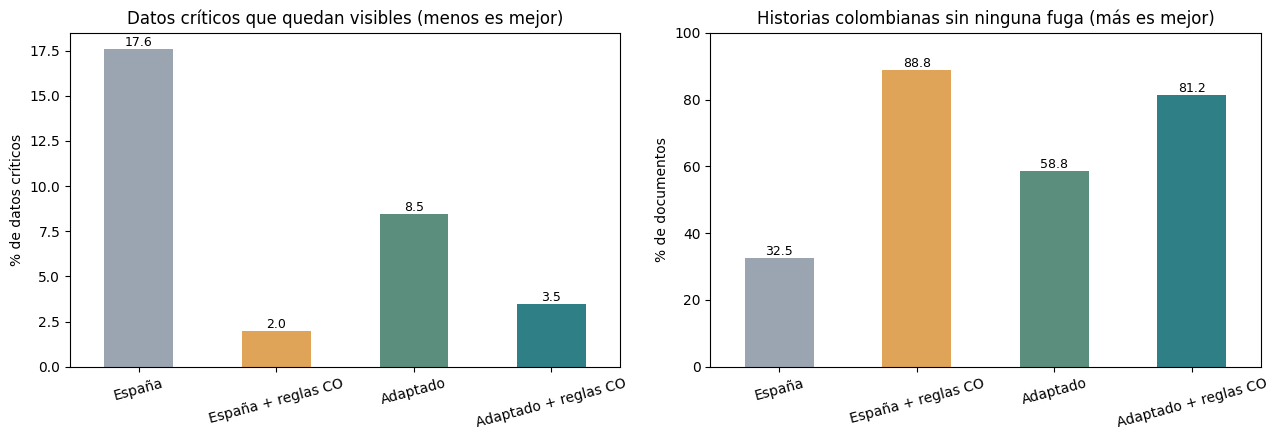

,tipo,datos,fugas España,fugas Adaptado + reglas CO
0,NOMBRE_SUJETO_ASISTENCIA,130,5,10
1,NOMBRE_PERSONAL_SANITARIO,90,0,0
2,ID_SUJETO_ASISTENCIA,70,23,0
3,NUMERO_TELEFONO,60,17,0
4,ID_TITULACION_PERSONAL_SANITARIO,50,22,0
5,CALLE,40,10,0
6,CORREO_ELECTRONICO,10,0,0
7,ID_CONTACTO_ASISTENCIAL,10,4,6


In [37]:
def f1_meddocan(modelo_x, reglas=None):
    """F1 estricto por documento sobre la prueba oficial de MEDDOCAN."""
    pred = {doc: predecir_con(modelo_x, textos[doc], reglas) for doc in gold_por_doc}
    return resumen(evaluar(gold_por_doc, pred, estricto=True))["f1"]


sistemas = {
    "España": (modelo_es, None),
    "España + reglas CO": (modelo_es, spans_reglas_co),
    "Adaptado": (modelo_co, None),
    "Adaptado + reglas CO": (modelo_co, spans_reglas_co),
}

filas_comp, fugas_por_sistema = [], {}
for nombre, (modelo_x, reglas) in sistemas.items():
    pred = {doc: predecir_con(modelo_x, t, reglas) for doc, t in textos_co.items()}
    met, fugadas = evaluar_colombia(pred)
    fugas_por_sistema[nombre] = fugadas
    filas_comp.append({"Sistema": nombre, "F1 MEDDOCAN (España)": f1_meddocan(modelo_x, reglas), **met})

tabla_co = pd.DataFrame(filas_comp).set_index("Sistema")
display(tabla_co.round(3))
tabla_co.to_csv(DATA_CO / "comparacion_espana_colombia.csv", sep=";", encoding="utf-8-sig")

# Gráfica: fuga crítica y documentos sin fuga para cada sistema.
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
colores = ["#9AA5B1", "#E0A458", "#5B8E7D", "#2F7F86"]
tabla_co["Fuga crítica (%)"].plot.bar(ax=ejes[0], color=colores)
ejes[0].set_title("Datos críticos que quedan visibles (menos es mejor)")
ejes[0].set_ylabel("% de datos críticos")
tabla_co["Docs sin fuga (%)"].plot.bar(ax=ejes[1], color=colores)
ejes[1].set_title("Historias colombianas sin ninguna fuga (más es mejor)")
ejes[1].set_ylabel("% de documentos")
ejes[1].set_ylim(0, 100)
for ax in ejes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
    for barra in ax.patches:
        ax.annotate(f"{barra.get_height():.1f}", (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                    ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

# Qué tipos se siguen fugando en el sistema final.
final = "Adaptado + reglas CO"
criticas_por_tipo = Counter(e["type"] for es in gold_co.values() for e in es if e["type"] in CRITICOS)
fugas_por_tipo = pd.DataFrame([
    {"tipo": t, "datos": n,
     "fugas España": sum(f["tipo"] == t for f in fugas_por_sistema["España"]),
     f"fugas {final}": sum(f["tipo"] == t for f in fugas_por_sistema[final])}
    for t, n in criticas_por_tipo.most_common()
])
display(fugas_por_tipo)

### 8.7 · Demostración con una nota colombiana

Una nota escrita a mano, sin rótulos y con formatos colombianos. Comparamos lo que deja
visible el modelo de España y lo que deja el sistema final.

In [38]:
NOTA_CO = """Nota de evolución 14/11/2025. Paciente femenina de 67 años, residente en el barrio
Patio Bonito de Bogotá, afiliada a Nueva EPS, identificada con CC 41.765.230. Ingresó traída
por su hija Yuliana Rocío Bermúdez, quien deja el celular 312 455 8890 y la dirección
Cra. 86 # 38C-21 Sur, apto 402. Se comenta el caso con el Dr. Hernán Darío Pinzón (RM 15342-08)
del Hospital Occidente de Kennedy, quien recomienda continuar ceftriaxona y control en 48 horas."""


def anonimizar_con(modelo_x, texto, reglas=None):
    """Reemplaza los datos detectados por etiquetas legibles."""
    spans = predecir_con(modelo_x, texto, reglas)
    salida = texto
    for span in sorted(spans, key=lambda s: s["start"], reverse=True):
        salida = salida[:span["start"]] + f"[{GRUPOS.get(span['type'], 'OTRO')}]" + salida[span["end"]:]
    return salida


print("MODELO DE ESPAÑA\n")
print(anonimizar_con(modelo_es, NOTA_CO))
print("\n" + "-" * 90 + "\nSISTEMA FINAL (adaptado + reglas colombianas)\n")
print(anonimizar_con(modelo_co, NOTA_CO, reglas=spans_reglas_co))

MODELO DE ESPAÑA

Nota de evolución [FECHA]. Paciente [OTRO] de [OTRO], residente en el [LUGAR] de [LUGAR], afiliada a Nueva EPS, identificada con CC [IDENTIFICACIÓN]. Ingresó traída
por su [NOMBRE][NOMBRE], quien deja el celular [CONTACTO] y la dirección
[LUGAR], [LUGAR]. Se comenta el caso con el Dr. [NOMBRE] (RM [IDENTIFICACIÓN])
del [LUGAR], quien recomienda continuar ceftriaxona y control en 48 horas.

------------------------------------------------------------------------------------------
SISTEMA FINAL (adaptado + reglas colombianas)

Nota de evolución [FECHA]. Paciente [OTRO] de [OTRO], residente en el [LUGAR] de [LUGAR], afiliada a [LUGAR], identificada con [IDENTIFICACIÓN]. Ingresó traída
por su [NOMBRE], quien deja el celular [CONTACTO] y la dirección
[LUGAR]. Se comenta el caso con el Dr. [NOMBRE] ([IDENTIFICACIÓN])
del [LUGAR], quien recomienda continuar ceftriaxona y control en 48 horas.


### Qué reportar de la Caja 8

- **El problema:** cuánto se fuga el modelo de España con historias colombianas (fila 1 de la
  tabla de 8.6) frente a lo que logra con MEDDOCAN.
- **El aporte:** cuánto bajan la fuga crítica y suben los documentos sin fuga al agregar
  reglas colombianas y aumento de datos (filas 2 a 4), sin perder F1 en MEDDOCAN.
- **Dónde mirar con lupa:** en la tabla de fugas por tipo, los nombres son el dato que las
  reglas no cubren. Si la fuga de nombres baja entre "España" y "Adaptado", la mejora viene del
  aumento de datos y no solo de las reglas.
- **Lo que falta:** el conjunto colombiano es sintético. El siguiente paso sería validarlo con
  historias reales anonimizadas por una clínica, revisadas por una persona.

## Caja 9 · Mejorar el F1 y cambiar de modelo

**Entra:** el modelo BETO adaptado de la Caja 8 y el corpus mixto (España + copias colombianas).
**Sale:** un sistema mejorado y una tabla que compara cada cambio por separado.
**Herramienta:** postproceso sobre las predicciones y un segundo modelo, RoBERTa clínico.

Dos frentes:

1. **Mejoras sin reentrenar** (9.1 y 9.2), que actúan sobre las predicciones:
   - **Tipo por contexto:** si antes del número dice `CC` es una cédula; si dice `RM`, un registro
     médico. Ataca el F1 con tipo en Colombia, donde el modelo confundía clases.
   - **Regla de número de ingreso:** cubre el único dato con formato fijo que seguía fugándose.
   - **Propagación:** si el modelo encontró un nombre una vez, se tapa en todo el documento.
   - **Umbral de recall:** un token se marca como dato si la probabilidad de "no es dato" es
     menor que un umbral. El umbral se elige en **validación**, nunca en prueba.
2. **Cambio de modelo** (9.3): `PlanTL-GOB-ES/roberta-base-biomedical-clinical-es`, un RoBERTa
   preentrenado con textos biomédicos y **clínicos** en español, del mismo grupo que creó
   MEDDOCAN. Se entrena desde su versión base con el corpus mixto de la Caja 8.

> En una GPU T4 el entrenamiento de RoBERTa tarda unos 25 minutos.

In [39]:
# ---------------------------------------------------------------------------
# 9.0 · Probabilidades por documento (se calculan una vez y se reutilizan)
# ---------------------------------------------------------------------------
ID_O = label2id["O"]


def probabilidades(modelo_x, tok, texto):
    """Devuelve, por ventana, los offsets y la probabilidad de cada etiqueta."""
    cod = tok(texto, max_length=MAX_LEN, stride=STRIDE, truncation=True,
              return_overflowing_tokens=True, return_offsets_mapping=True,
              add_special_tokens=True)
    ventanas = []
    modelo_x.eval()
    with torch.no_grad():
        for i in range(len(cod["input_ids"])):
            entrada = {
                "input_ids": torch.tensor([cod["input_ids"][i]]).to(DISPOSITIVO),
                "attention_mask": torch.tensor([cod["attention_mask"][i]]).to(DISPOSITIVO),
            }
            p = torch.softmax(modelo_x(**entrada).logits[0].float(), dim=-1)
            ventanas.append((cod["offset_mapping"][i], p.cpu().numpy().astype(np.float16)))
    return ventanas


def decodificar(ventanas, texto, umbral=0.0):
    """Convierte probabilidades en spans.

    Con umbral=0 es la decisión normal (la etiqueta más probable). Con umbral>0,
    un token que iba a quedar como O pasa a la mejor etiqueta de dato si la
    probabilidad de O es menor que el umbral.
    """
    spans = []
    for offsets, p in ventanas:
        p = p.astype(np.float32)
        etiquetas_v = p.argmax(-1)
        if umbral > 0:
            sin_o = p.copy()
            sin_o[:, ID_O] = -1.0
            cambiar = (etiquetas_v == ID_O) & (p[:, ID_O] < umbral)
            etiquetas_v = np.where(cambiar, sin_o.argmax(-1), etiquetas_v)
        # Los tokens especiales (<s>, </s>, [CLS], [SEP]) nunca son datos.
        etiquetas_v = np.array([ID_O if e <= s else t
                                for (s, e), t in zip(offsets, etiquetas_v)])
        for span in spans_de_etiquetas(offsets, etiquetas_v):
            span = recortar(span, texto)
            if span["end"] > span["start"] and validar_span(span, texto):
                spans.append(span)
    return sin_solapes(deduplicar(spans))


def cache_de(modelo_x, tok, textos_dict):
    """Probabilidades de un modelo para un diccionario {documento: texto}."""
    return {doc: probabilidades(modelo_x, tok, t) for doc, t in textos_dict.items()}


# Conjuntos que vamos a evaluar
val_docs = originales["validación"] + aumentados["validación"]
textos_val = {r["id"]: r["text"] for r in val_docs}
gold_val = {r["id"]: r["entities"] for r in val_docs}
textos_meddocan = {doc: textos[doc] for doc in gold_por_doc}

cache = {"BETO": {
    "val": cache_de(modelo_co, tokenizer, textos_val),
    "meddocan": cache_de(modelo_co, tokenizer, textos_meddocan),
    "colombia": cache_de(modelo_co, tokenizer, textos_co),
}}
print("Probabilidades de BETO adaptado listas:",
      {k: len(v) for k, v in cache["BETO"].items()}, "documentos")

Probabilidades de BETO adaptado listas: {'val': 500, 'meddocan': 250, 'colombia': 80} documentos


### 9.1 · Tipo por contexto, regla de ingreso y propagación

Las tres mejoras miran el texto alrededor de cada predicción:

| Mejora | Ejemplo | Efecto esperado |
|---|---|---|
| Tipo por contexto | `RM 52345-09` marcado como cédula → pasa a `ID_TITULACION_PERSONAL_SANITARIO` | Sube el F1 con tipo |
| Regla de ingreso | `Ingreso n.º 4587213` | Elimina esa fuga |
| Propagación | Se detectó `Ximena López` en el encabezado → también se tapa más abajo | Baja la fuga de nombres |

El tipo por contexto solo cambia predicciones que son casi solo dígitos, y respeta las
convenciones del corpus (`NHC` es identificación del paciente, `NASS` es aseguramiento y
`NºCol` es titulación del médico).

In [40]:
# ---------------------------------------------------------------------------
# Regla adicional: número de ingreso o episodio
# ---------------------------------------------------------------------------
REGLAS_CO_V2 = REGLAS_CO + [
    ("ID_CONTACTO_ASISTENCIAL", re.compile(
        r"\b(?:ingreso|episodio|admisi[oó]n)\s*(?:n\.?\s?[°º]|No\.?|n[uú]mero)\s*:?\s*(\d{4,})", re.I)),
]


def spans_reglas_v2(texto):
    spans = []
    for tipo, patron in REGLAS_CO_V2:
        for m in patron.finditer(texto):
            if tipo == "FECHAS" or not (m.groups() and m.group(1)):
                ini, fin = m.span()
            else:
                ini, fin = m.span(1)
            spans.append({"start": ini, "end": fin, "type": tipo})
    return sin_solapes(spans)


# ---------------------------------------------------------------------------
# Tipo por contexto: el rótulo que precede al número decide el tipo
# ---------------------------------------------------------------------------
_N = r"\s*(?:n\.?\s?[°º]\.?|No\.?|n[uú]mero)?\s*:?\s*$"
CONTEXTO_TIPO = [
    (re.compile(r"(?:ingreso|episodio|admisi[oó]n)" + _N, re.I), "ID_CONTACTO_ASISTENCIAL"),
    (re.compile(r"(?:\bRM|R\.M\.|registro\s+m[ée]dico|\bTP|T\.P\.|tarjeta\s+profesional|"
                r"N[ºo°]\s?Col)" + _N, re.I), "ID_TITULACION_PERSONAL_SANITARIO"),
    (re.compile(r"(?:NASS|afiliaci[oó]n|carn[ée](?:\s+EPS)?)" + _N, re.I), "ID_ASEGURAMIENTO"),
    (re.compile(r"(?:\bC\.?\s?C\.?|\bT\.?\s?I\.?|c[ée]dula(?:\s+de\s+ciudadan[ií]a)?|documento|"
                r"identificaci[oó]n|historia\s+cl[ií]nica|\bN?HC|historia|"
                r"identificad[oa]\s+con)" + _N, re.I), "ID_SUJETO_ASISTENCIA"),
    (re.compile(r"(?:tel[ée]fono|\btel\.?|celular|\bcel\.?|m[óo]vil|fijo)"
                r"(?:\s+de\s+contacto)?" + _N, re.I), "NUMERO_TELEFONO"),
]

# Solo se corrigen identificadores y teléfonos. Fechas, edades y códigos postales
# también son números, pero su tipo no depende del rótulo: "Fecha de Ingreso:
# 12/12/2016" es una fecha, no un número de ingreso.
TIPOS_CORREGIBLES = {
    "ID_SUJETO_ASISTENCIA", "ID_ASEGURAMIENTO", "ID_TITULACION_PERSONAL_SANITARIO",
    "ID_CONTACTO_ASISTENCIAL", "ID_EMPLEO_PERSONAL_SANITARIO", "NUMERO_TELEFONO", "NUMERO_FAX",
}


def corregir_tipo(spans, texto):
    """Cambia el tipo de un identificador según el rótulo que tiene justo antes."""
    corregidos = []
    for s in spans:
        frag = texto[s["start"]:s["end"]]
        digitos = sum(c.isdigit() for c in frag)
        letras = sum(c.isalpha() for c in frag)
        nuevo = dict(s)
        if s["type"] in TIPOS_CORREGIBLES and digitos >= 4 and letras <= 3:
            antes = texto[max(0, s["start"] - 35):s["start"]]
            for patron, tipo in CONTEXTO_TIPO:
                if patron.search(antes):
                    nuevo["type"] = tipo
                    break
        corregidos.append(nuevo)
    return corregidos

# ---------------------------------------------------------------------------
# Propagación: lo que se detectó una vez se tapa en todo el documento
# ---------------------------------------------------------------------------
PROPAGABLES = {
    "NOMBRE_SUJETO_ASISTENCIA", "NOMBRE_PERSONAL_SANITARIO", "ID_SUJETO_ASISTENCIA",
    "ID_TITULACION_PERSONAL_SANITARIO", "ID_ASEGURAMIENTO", "ID_CONTACTO_ASISTENCIAL",
    "CALLE", "CORREO_ELECTRONICO", "NUMERO_TELEFONO",
}


def propagar_entidades(spans, texto):
    cadenas = {}
    for s in spans:
        if s["type"] not in PROPAGABLES:
            continue
        frag = texto[s["start"]:s["end"]]
        if len(frag) >= 4:
            cadenas.setdefault(frag, s["type"])
        if s["type"].startswith("NOMBRE"):
            # Cada nombre o apellido por separado: "Ximena López" tapa también "Ximena".
            for palabra in re.findall(r"[A-ZÁÉÍÓÚÑ][a-záéíóúñü]{3,}", frag):
                cadenas.setdefault(palabra, s["type"])
    nuevos = list(spans)
    for frag, tipo in cadenas.items():
        for m in re.finditer(rf"(?<!\w){re.escape(frag)}(?!\w)", texto):
            candidato = {"start": m.start(), "end": m.end(), "type": tipo}
            if not any(solapan(candidato, p) > 0 for p in nuevos):
                nuevos.append(candidato)
    return sorted(nuevos, key=lambda s: s["start"])


def sistema(ventanas, texto, reglas=None, umbral=0.0, contexto=False, propagar=False):
    """Une todas las piezas en el orden en que se aplican."""
    spans = decodificar(ventanas, texto, umbral)
    if reglas:
        spans = fusionar(spans, reglas(texto), texto)
    if propagar:
        spans = propagar_entidades(spans, texto)
    if contexto:
        spans = corregir_tipo(spans, texto)
    return spans


# Prueba rápida de la corrección de tipo
ejemplo_tipo = "Firma: Dr. Pérez, RM 52345-09. Paciente CC 1.024.567.890. Ingreso n.º 4587213."
falsos = [{"start": m.start(), "end": m.end(), "type": "NUMERO_TELEFONO"}
          for m in re.finditer(r"\d[\d.-]{5,}\d", ejemplo_tipo)]
for s in corregir_tipo(falsos, ejemplo_tipo):
    print(f"{ejemplo_tipo[s['start']:s['end']]:<16} NUMERO_TELEFONO -> {s['type']}")

52345-09         NUMERO_TELEFONO -> ID_TITULACION_PERSONAL_SANITARIO
1.024.567.890    NUMERO_TELEFONO -> ID_SUJETO_ASISTENCIA
4587213          NUMERO_TELEFONO -> ID_CONTACTO_ASISTENCIAL


### 9.2 · Elegir el umbral de recall en validación

Probamos varios umbrales sobre la **validación mixta** (250 documentos de España y sus 250
copias colombianas). Elegimos el umbral con **mayor recall** que no baje el F1 más de medio
punto frente a la decisión normal. Así el umbral no se ajusta mirando la prueba.

In [41]:
UMBRALES = [0.0, 0.5, 0.7, 0.9, 0.97]


def elegir_umbral(cache_val, nombre):
    filas = []
    for u in UMBRALES:
        pred = {d: sistema(cache_val[d], textos_val[d], umbral=u) for d in gold_val}
        r = resumen(evaluar(gold_val, pred, estricto=False))
        filas.append({"umbral": u, "precision": r["precision"], "recall": r["recall"], "f1": r["f1"]})
    tabla = pd.DataFrame(filas)
    base = tabla.loc[tabla["umbral"] == 0.0, "f1"].iloc[0]
    aptos = tabla[tabla["f1"] >= base - 0.005]
    elegido = float(aptos.sort_values(["recall", "f1"], ascending=False)["umbral"].iloc[0])
    print(f"{nombre}: umbral elegido = {elegido}")
    display(tabla.round(4))
    return elegido


UMBRAL = {"BETO": elegir_umbral(cache["BETO"]["val"], "BETO adaptado")}

BETO adaptado: umbral elegido = 0.9


,umbral,precision,recall,f1
0,0.00,0.9764,0.9825,0.9795
1,0.50,0.9744,0.9828,0.9785
2,0.70,0.9720,0.9833,0.9776
3,0.90,0.9681,0.9841,0.9761
4,0.97,0.9641,0.9840,0.9739


### 9.3 · Cambiar el modelo: RoBERTa clínico en español

`PlanTL-GOB-ES/roberta-base-biomedical-clinical-es` es del Plan de Tecnologías del Lenguaje
del gobierno español y del Barcelona Supercomputing Center, el mismo grupo que publicó
MEDDOCAN. A diferencia de BETO, que aprendió español general, este modelo se preentrenó con
artículos biomédicos y **notas clínicas**: conoce mejor el vocabulario y la forma en que se
escriben las historias.

Usa un tokenizador distinto (BPE por bytes), así que primero comprobamos que las etiquetas BIO
sigan cayendo en los tokens correctos. Luego lo entrenamos con el **mismo corpus mixto** de
la Caja 8.

> **Comparación justa:** BETO adaptado recibió 10 épocas con España + 3 con el corpus mixto.
> RoBERTa parte de su versión base y recibe 6 épocas con el corpus mixto.

In [42]:
from transformers import AutoTokenizer

MODELO_ROB = "PlanTL-GOB-ES/roberta-base-biomedical-clinical-es"
EPOCHS_ROB = 1 if MODO_RAPIDO else 6
SALIDA_ROB = BASE / ("models/rapido-rob" if MODO_RAPIDO else "models/roberta-clinico-co")
SALIDA_ROB.mkdir(parents=True, exist_ok=True)

tok_rob = AutoTokenizer.from_pretrained(MODELO_ROB)
assert tok_rob.is_fast, "Se necesita un tokenizador rápido para obtener los offsets"

# Misma frase de la Caja 2: ¿las etiquetas caen en los tokens correctos?
cod = tok_rob(frase, return_offsets_mapping=True, add_special_tokens=True)
etq = alinear(cod["offset_mapping"], spans_frase, label2id)
display(pd.DataFrame([
    {"token": tok_rob.convert_ids_to_tokens(t), "inicio": s, "fin": e,
     "etiqueta": id2label.get(x, "ignorado (-100)")}
    for t, (s, e), x in zip(cod["input_ids"], cod["offset_mapping"], etq) if e > s
]))


def construir_con(lista, tok):
    filas = []
    for r in lista:
        for fila in codificar(r, tok, MAX_LEN, STRIDE, label2id):
            fila.pop("offsets")
            filas.append(fila)
    return Dataset.from_list(filas)


def entidades_sin_b(lista, tok):
    """Cuenta entidades que no reciben su etiqueta B- en ninguna ventana."""
    faltan = 0
    for r in lista:
        filas = codificar(r, tok, MAX_LEN, STRIDE, label2id)
        for ent in r["entities"]:
            ok = False
            for f in filas:
                idx = [i for i, (s, _) in enumerate(f["offsets"]) if ent["start"] <= s < ent["end"]]
                if idx and f["labels"][idx[0]] != -100 and id2label[f["labels"][idx[0]]] == f"B-{ent['type']}":
                    ok = True
                    break
            faltan += not ok
    return faltan


print("Entidades sin B- con el tokenizador de RoBERTa (50 documentos):",
      entidades_sin_b(originales["entrenamiento"][:50], tok_rob))

train_rob = construir_con(originales["entrenamiento"] + aumentados["entrenamiento"], tok_rob)
val_rob = construir_con(originales["validación"] + aumentados["validación"], tok_rob)
print(f"Ventanas RoBERTa: train={len(train_rob)} val={len(val_rob)}")

config.json:   0%|          | 0.00/613 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.27k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.22M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/540k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/772 [00:00<?, ?B/s]

,token,inicio,fin,etiqueta
0,ĠIngreso,0,7,O
1,Ġel,8,10,B-NOMBRE_SUJETO_ASISTENCIA
2,Ġ12,11,13,I-NOMBRE_SUJETO_ASISTENCIA
3,Ġde,14,16,I-NOMBRE_SUJETO_ASISTENCIA
4,Ġmarzo,17,22,O
5,Ġde,23,25,ignorado (-100)
6,Ġ20,26,28,ignorado (-100)
7,24,28,30,O
8,Ġpor,31,34,O
9,Ġurgencias,35,44,O


Entidades sin B- con el tokenizador de RoBERTa (50 documentos): 0
Ventanas RoBERTa: train=1822 val=964


In [43]:
modelo_rob = AutoModelForTokenClassification.from_pretrained(
    MODELO_ROB, num_labels=len(etiquetas), id2label=id2label, label2id=label2id,
).to(DISPOSITIVO)

argumentos_rob = TrainingArguments(
    output_dir=str(SALIDA_ROB),
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=20,
    learning_rate=3e-5,              # RoBERTa suele afinar mejor con una tasa algo mayor
    per_device_train_batch_size=lote,
    per_device_eval_batch_size=lote * 2,
    num_train_epochs=EPOCHS_ROB,
    weight_decay=0.01,
    warmup_steps=1 if MODO_RAPIDO else 50,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    save_total_limit=1,
    fp16=(DISPOSITIVO == "cuda"),
    seed=SEED,
    data_seed=SEED,
    report_to="none",
    dataloader_num_workers=0,
    label_names=["labels"],
)

entrenador_rob = Trainer(
    model=modelo_rob,
    args=argumentos_rob,
    train_dataset=train_rob,
    eval_dataset=val_rob,
    data_collator=Lotes(tok_rob.pad_token_id),
    compute_metrics=metricas,
    processing_class=tok_rob,
)
entrenador_rob.train()

print("\nValidación mixta (RoBERTa clínico):")
for clave, valor in entrenador_rob.evaluate(val_rob).items():
    if isinstance(valor, float) and not clave.endswith("runtime"):
        print(f"  {clave}: {valor:.4f}")

entrenador_rob.save_model(SALIDA_ROB)
tok_rob.save_pretrained(SALIDA_ROB)
(SALIDA_ROB / "labels.json").write_text((SALIDA / "labels.json").read_text(encoding="utf-8"),
                                        encoding="utf-8")
modelo_rob = entrenador_rob.model
print("RoBERTa clínico guardado en", SALIDA_ROB)

cache["RoBERTa"] = {
    "val": cache_de(modelo_rob, tok_rob, textos_val),
    "meddocan": cache_de(modelo_rob, tok_rob, textos_meddocan),
    "colombia": cache_de(modelo_rob, tok_rob, textos_co),
}
UMBRAL["RoBERTa"] = elegir_umbral(cache["RoBERTa"]["val"], "RoBERTa clínico")

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  504MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForTokenClassification LOAD REPORT from: PlanTL-GOB-ES/roberta-base-biomedical-clinical-es
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.decoder.weight    | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.decoder.bias      | UNEXPECTED | 
classifier.bias           | MISSING    | 
classifier.weight         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,F1,Precision,Recall,F1 Macro,Accuracy
1,0.331569,0.193634,0.510183,0.479108,0.545569,0.256733,0.962085
2,0.064167,0.044299,0.924692,0.916139,0.933406,0.585863,0.994065
3,0.035386,0.029883,0.931845,0.916484,0.947730,0.625731,0.995820
4,0.027222,0.025679,0.946270,0.935352,0.957447,0.680424,0.996316
5,0.022316,0.023135,0.954283,0.946151,0.962557,0.698420,0.996796
6,0.020452,0.022829,0.953387,0.943265,0.963729,0.697961,0.996722


model.safetensors: reconstructing file:   0%|          |  0.00B /  504MB            

... (9 outputs left out)

  eval_loss: 0.0231
  eval_f1: 0.9543
  eval_precision: 0.9462
  eval_recall: 0.9626
  eval_f1_macro: 0.6984
  eval_accuracy: 0.9968


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

RoBERTa clínico guardado en /content/models/roberta-clinico-co
RoBERTa clínico: umbral elegido = 0.9


,umbral,precision,recall,f1
0,0.00,0.9689,0.9735,0.9712
1,0.50,0.9650,0.9738,0.9694
2,0.70,0.9636,0.9741,0.9688
3,0.90,0.9589,0.9744,0.9666
4,0.97,0.9534,0.9745,0.9638


### 9.4 · Comparación final

Seis sistemas, evaluados con las mismas funciones:

| Fila | Modelo | Reglas | Mejoras 9.1 y 9.2 |
|---|---|---|---|
| 1 | BETO adaptado | — | — |
| 2 | BETO adaptado | reglas CO | — (sistema final de la Caja 8) |
| 3 | BETO adaptado | reglas CO + ingreso | tipo, propagación y umbral |
| 4 | RoBERTa clínico | — | — |
| 5 | RoBERTa clínico | reglas CO | — |
| 6 | RoBERTa clínico | reglas CO + ingreso | tipo, propagación y umbral |

Además del F1 de 22 clases, reportamos el **F1 por grupo de la aplicación** (los 6 reemplazos:
`[NOMBRE]`, `[IDENTIFICACIÓN]`, `[CONTACTO]`, `[LUGAR]`, `[FECHA]`, `[OTRO]`). Confundir
`HOSPITAL` con `INSTITUCION` no cambia nada para el usuario, porque los dos se reemplazan por
`[LUGAR]`. Este F1 complementa al de 22 clases; no lo reemplaza.

,MEDDOCAN F1,MEDDOCAN F1 macro,MEDDOCAN F1 por grupo,Colombia F1 (con tipo),Colombia F1 sin tipo,Fuga crítica (%),Docs sin fuga (%)
Sistema,,,,,,,
BETO adaptado,0.966,0.816,0.968,0.657,0.853,8.478,58.75
BETO adaptado + reglas CO,0.966,0.816,0.968,0.696,0.885,3.478,81.25
BETO adaptado + reglas + mejoras,0.961,0.809,0.964,0.715,0.871,2.174,88.75
RoBERTa clínico,0.957,0.731,0.961,0.629,0.850,8.043,61.25
RoBERTa clínico + reglas CO,0.957,0.730,0.961,0.661,0.867,2.391,87.50
RoBERTa clínico + reglas + mejoras,0.951,0.725,0.955,0.663,0.819,2.391,87.50


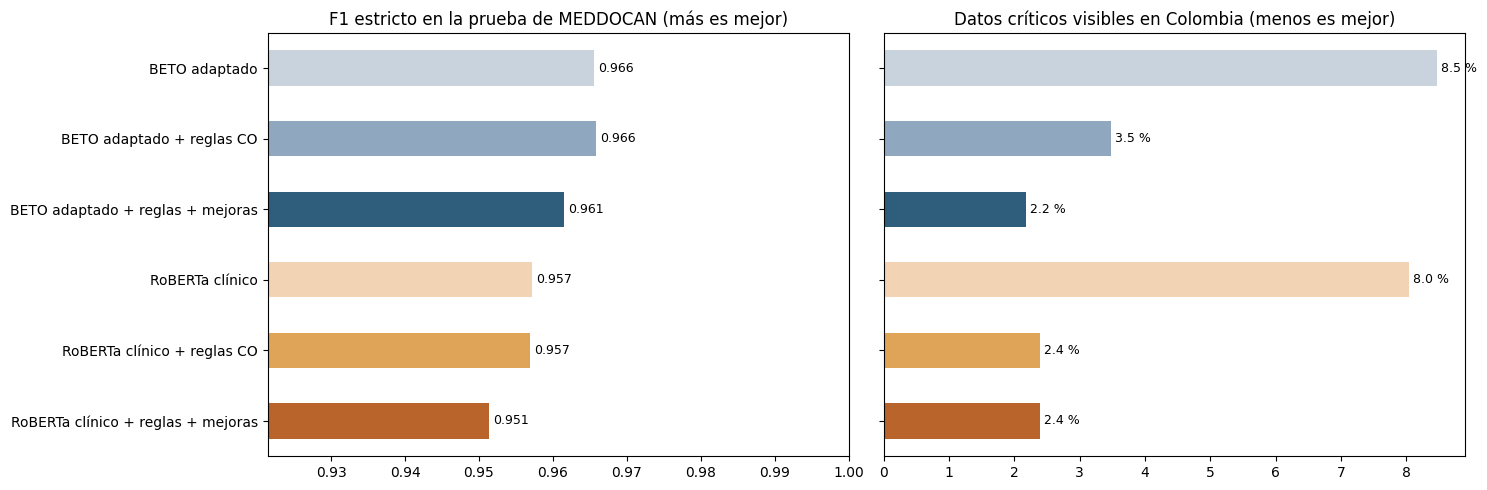

In [44]:
def f1_por_grupo(gold, pred):
    """F1 estricto en límites, pero comparando el grupo de la aplicación."""
    tp = fp = fn = 0
    for doc, reales in gold.items():
        predichas = pred.get(doc, [])
        usadas = set()
        for g_ in reales:
            elegida = next((i for i, p in enumerate(predichas)
                            if i not in usadas and p["start"] == g_["start"] and p["end"] == g_["end"]
                            and GRUPOS.get(p["type"]) == GRUPOS.get(g_["type"])), None)
            if elegida is None:
                fn += 1
            else:
                usadas.add(elegida)
                tp += 1
        fp += len(predichas) - len(usadas)
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    return 2 * p * r / (p + r) if p + r else 0.0


CONFIGURACIONES = [
    ("BETO adaptado", "BETO", dict()),
    ("BETO adaptado + reglas CO", "BETO", dict(reglas=spans_reglas_co)),
    ("BETO adaptado + reglas + mejoras", "BETO", dict(reglas=spans_reglas_v2, contexto=True, propagar=True, umbral="auto")),
    ("RoBERTa clínico", "RoBERTa", dict()),
    ("RoBERTa clínico + reglas CO", "RoBERTa", dict(reglas=spans_reglas_co)),
    ("RoBERTa clínico + reglas + mejoras", "RoBERTa", dict(reglas=spans_reglas_v2, contexto=True, propagar=True, umbral="auto")),
]

filas_final, preds_final, fugas_final = [], {}, {}
for nombre, modelo_nombre, opciones in CONFIGURACIONES:
    opciones = dict(opciones)
    if opciones.get("umbral") == "auto":
        opciones["umbral"] = UMBRAL[modelo_nombre]
    c = cache[modelo_nombre]
    pred_m = {d: sistema(c["meddocan"][d], textos_meddocan[d], **opciones) for d in gold_por_doc}
    pred_c = {d: sistema(c["colombia"][d], textos_co[d], **opciones) for d in gold_co}
    preds_final[nombre] = pred_m
    r_m = resumen(evaluar(gold_por_doc, pred_m, estricto=True))
    met_co, fugadas = evaluar_colombia(pred_c)
    fugas_final[nombre] = fugadas
    filas_final.append({
        "Sistema": nombre,
        "MEDDOCAN F1": r_m["f1"],
        "MEDDOCAN F1 macro": r_m["f1_macro"],
        "MEDDOCAN F1 por grupo": f1_por_grupo(gold_por_doc, pred_m),
        "Colombia F1 (con tipo)": met_co["F1 relajado (con tipo)"],
        "Colombia F1 sin tipo": met_co["F1 sin tipo"],
        "Fuga crítica (%)": met_co["Fuga crítica (%)"],
        "Docs sin fuga (%)": met_co["Docs sin fuga (%)"],
    })

tabla_final = pd.DataFrame(filas_final).set_index("Sistema")
display(tabla_final.round(3))
tabla_final.to_csv(DATA_CO / "comparacion_final.csv", sep=";", encoding="utf-8-sig")

# Gráfica: F1 en España y fuga en Colombia para cada sistema
fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
colores = ["#C9D3DD", "#8FA8BF", "#2F5D7C", "#F2D3B3", "#E0A458", "#B8642A"]
tabla_final["MEDDOCAN F1"].plot.barh(ax=ejes[0], color=colores)
ejes[0].set_xlim(max(0.0, tabla_final["MEDDOCAN F1"].min() - 0.03), 1.0)
ejes[0].set_title("F1 estricto en la prueba de MEDDOCAN (más es mejor)")
tabla_final["Fuga crítica (%)"].plot.barh(ax=ejes[1], color=colores)
ejes[1].set_title("Datos críticos visibles en Colombia (menos es mejor)")
for ax in ejes:
    ax.invert_yaxis()
    ax.set_ylabel("")
    for barra in ax.patches:
        ax.annotate(f"{barra.get_width():.3f}" if ax is ejes[0] else f"{barra.get_width():.1f} %",
                    (barra.get_width(), barra.get_y() + barra.get_height() / 2),
                    va="center", ha="left", fontsize=9, xytext=(3, 0), textcoords="offset points")
ejes[1].set_yticklabels([])
plt.tight_layout()
plt.show()

In [45]:
# ---------------------------------------------------------------------------
# F1 por tipo en MEDDOCAN: dónde ayudó cada cambio
# ---------------------------------------------------------------------------
def f1_tipo(pred):
    filas = {}
    for tipo, s in evaluar(gold_por_doc, pred, estricto=True).items():
        p = s["tp"] / (s["tp"] + s["fp"]) if s["tp"] + s["fp"] else 0.0
        r = s["tp"] / (s["tp"] + s["fn"]) if s["tp"] + s["fn"] else 0.0
        filas[tipo] = 2 * p * r / (p + r) if p + r else 0.0
    return filas


soporte = Counter(e["type"] for es in gold_por_doc.values() for e in es)
comparar = ["BETO adaptado + reglas CO", "RoBERTa clínico", "RoBERTa clínico + reglas + mejoras"]
tabla_tipos_final = pd.DataFrame({n: f1_tipo(preds_final[n]) for n in comparar})
tabla_tipos_final["soporte"] = [soporte.get(t, 0) for t in tabla_tipos_final.index]
tabla_tipos_final = tabla_tipos_final[tabla_tipos_final["soporte"] > 0].sort_values("soporte", ascending=False)
display(tabla_tipos_final.round(3))

# Lo que todavía se fuga en Colombia con el mejor sistema
mejor = tabla_final["Fuga crítica (%)"].idxmin()
print(f"\nSistema con menor fuga en Colombia: {mejor}")
display(pd.DataFrame(fugas_final[mejor]) if fugas_final[mejor] else "Ninguna fuga crítica")

,BETO adaptado + reglas CO,RoBERTa clínico,RoBERTa clínico + reglas + mejoras,soporte
TERRITORIO,0.972,0.964,0.963,956
FECHAS,0.993,0.993,0.993,611
EDAD_SUJETO_ASISTENCIA,0.982,0.972,0.963,518
NOMBRE_SUJETO_ASISTENCIA,0.998,0.996,0.996,502
NOMBRE_PERSONAL_SANITARIO,0.988,0.990,0.987,501
SEXO_SUJETO_ASISTENCIA,0.989,0.986,0.986,461
CALLE,0.946,0.939,0.938,413
PAIS,0.974,0.960,0.959,363
ID_SUJETO_ASISTENCIA,0.967,0.971,0.968,283
CORREO_ELECTRONICO,0.994,0.992,0.992,249



Sistema con menor fuga en Colombia: BETO adaptado + reglas + mejoras


,documento,tipo,texto
0,CO-005,NOMBRE_SUJETO_ASISTENCIA,Ximena López Jiménez
1,CO-005,NOMBRE_SUJETO_ASISTENCIA,Fredy López Hernández
2,CO-006,NOMBRE_SUJETO_ASISTENCIA,Fredy Sánchez Gómez
3,CO-009,NOMBRE_SUJETO_ASISTENCIA,Juliana Chaparro Herrera
4,CO-013,NOMBRE_SUJETO_ASISTENCIA,Ximena Ramírez
5,CO-021,NOMBRE_SUJETO_ASISTENCIA,Ximena Benavides López
6,CO-038,NOMBRE_SUJETO_ASISTENCIA,Fredy Herrera Carvajal
7,CO-047,NOMBRE_SUJETO_ASISTENCIA,Juliana Jiménez Carvajal
8,CO-070,NOMBRE_SUJETO_ASISTENCIA,Valentina Jiménez
9,CO-076,NOMBRE_SUJETO_ASISTENCIA,Adriana Benavides Sánchez


## Caja 10 · Exportar el sistema final para la demo

**Entra:** el BETO adaptado de la Caja 8, las reglas colombianas y el umbral elegido en la Caja 9.
**Sale:** una carpeta en Google Drive (y un zip) con todo lo que necesita la demo.
**Herramienta:** `save_pretrained` de Hugging Face y archivos JSON.

El sistema que exportamos es la fila **BETO adaptado + reglas + mejoras** de la tabla 9.4: el
modelo adaptado, las reglas colombianas con la regla de ingreso, el tipo por contexto, la
propagación y el umbral de recall. La carpeta queda así:

```
anonimizador_beto_co/
├── modelo/                 pesos, config y tokenizador (save_pretrained)
├── config_sistema.json     etiquetas, grupos, umbral, max_len, stride y métricas
├── reglas.json             expresiones regulares y listas del postproceso
├── resultados/             tablas de comparación y conjunto de prueba colombiano
└── LEEME.txt
```

La Caja 10 solo necesita que se hayan ejecutado las Cajas 0 a 9.2. Si no hubo tiempo de
entrenar RoBERTa (9.3 y 9.4), la exportación funciona igual y omite las métricas finales.

In [46]:
# ---------------------------------------------------------------------------
# 10.1 · Carpeta de destino y modelo
# ---------------------------------------------------------------------------
import shutil
from datetime import datetime

from transformers import AutoModelForTokenClassification, AutoTokenizer

SISTEMA_EXPORT = "BETO adaptado + reglas + mejoras"
OPCIONES_EXPORT = {"reglas": "reglas_co_v2", "contexto": True, "propagar": True}

# Si la celda de Drive no se ejecutó (por ejemplo, tras reiniciar), la repetimos aquí.
if "RAIZ_EXPORT" not in globals():
    NOMBRE_EXPORT, GUARDAR_ZIP = "anonimizador_beto_co", True
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        RAIZ_EXPORT = Path("/content/drive/MyDrive/meddocan-anon/export")
    except ImportError:
        RAIZ_EXPORT = BASE / "export"

DESTINO = RAIZ_EXPORT / NOMBRE_EXPORT
if DESTINO.exists():
    shutil.rmtree(DESTINO)          # cada exportación reemplaza a la anterior
(DESTINO / "modelo").mkdir(parents=True)
(DESTINO / "resultados").mkdir()

# modelo_co es el BETO adaptado que dejó la Caja 8.5 (el mejor checkpoint por F1).
# Si la sesión se reinició, lo recargamos desde el disco local.
if "modelo_co" not in globals():
    modelo_co = AutoModelForTokenClassification.from_pretrained(SALIDA_CO).to(DISPOSITIVO)

modelo_co.save_pretrained(DESTINO / "modelo")
tokenizer.save_pretrained(DESTINO / "modelo")
print("Modelo y tokenizador guardados en", DESTINO / "modelo")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modelo y tokenizador guardados en /content/drive/MyDrive/meddocan-anon/export/anonimizador_beto_co/modelo


In [47]:
# ---------------------------------------------------------------------------
# 10.2 · Configuración del sistema y reglas
# Las expresiones regulares se guardan como texto (patrón + flags) para que la
# demo las compile igual, sin copiar a mano ninguna regla.
# ---------------------------------------------------------------------------
def patron_a_dict(patron):
    return {"patron": patron.pattern, "flags": int(patron.flags)}


metricas_export = {}
if "tabla_final" in globals() and SISTEMA_EXPORT in tabla_final.index:
    metricas_export = {k: round(float(v), 4) for k, v in tabla_final.loc[SISTEMA_EXPORT].items()}

config_sistema = {
    "sistema": SISTEMA_EXPORT,
    "modelo_base": MODELO,
    "max_len": MAX_LEN,
    "stride": STRIDE,
    "umbral": float(UMBRAL["BETO"]),
    "opciones": OPCIONES_EXPORT,
    "labels": etiquetas,
    "label2id": label2id,
    "id2label": {str(k): v for k, v in id2label.items()},
    "grupos": GRUPOS,
    "metricas": metricas_export,
    "seed": SEED,
    "modo_rapido": MODO_RAPIDO,
    "fecha_exportacion": datetime.now().isoformat(timespec="seconds"),
}

reglas_export = {
    "reglas_co_v2": [{"tipo": t, **patron_a_dict(p)} for t, p in REGLAS_CO_V2],
    "contexto_tipo": [{"tipo": t, **patron_a_dict(p)} for p, t in CONTEXTO_TIPO],
    "tipos_corregibles": sorted(TIPOS_CORREGIBLES),
    "propagables": sorted(PROPAGABLES),
    "sexo_validos": sorted(SEXO_VALIDOS),
    "meses": MESES,
    "criticos": sorted(CRITICOS),
}

(DESTINO / "config_sistema.json").write_text(
    json.dumps(config_sistema, ensure_ascii=False, indent=2), encoding="utf-8")
(DESTINO / "reglas.json").write_text(
    json.dumps(reglas_export, ensure_ascii=False, indent=2), encoding="utf-8")

# Tablas de resultados y conjunto colombiano, para el informe y la sustentación.
for archivo in ["comparacion_espana_colombia.csv", "comparacion_final.csv",
                "prueba_colombia_documentos.csv", "prueba_colombia_anotaciones.csv"]:
    if (DATA_CO / archivo).exists():
        shutil.copy(DATA_CO / archivo, DESTINO / "resultados" / archivo)

(DESTINO / "LEEME.txt").write_text(
    f"""Anonimizador de historias clínicas (MEDDOCAN + adaptación a Colombia)
Sistema: {SISTEMA_EXPORT}
Modelo base: {MODELO}
Umbral de recall: {config_sistema['umbral']}
Exportado: {config_sistema['fecha_exportacion']}

Uso: abrir demo_anonimizacion.ipynb en Colab y ejecutar las tres celdas.
La demo busca esta carpeta en MyDrive/meddocan-anon/export/{NOMBRE_EXPORT}
o el archivo {NOMBRE_EXPORT}.zip subido a /content.
""", encoding="utf-8")

print(f"Umbral exportado: {config_sistema['umbral']}")
print(f"Reglas: {len(reglas_export['reglas_co_v2'])} patrones | "
      f"contexto: {len(reglas_export['contexto_tipo'])} rótulos")
print("Métricas del sistema:", metricas_export or "no disponibles (no se ejecutó la 9.4)")
if "mejor" in globals() and mejor != SISTEMA_EXPORT:
    print(f"Nota: en la tabla 9.4 la menor fuga la tiene '{mejor}'. "
          "Revisar si conviene cambiar SISTEMA_EXPORT.")

Umbral exportado: 0.9
Reglas: 10 patrones | contexto: 5 rótulos
Métricas del sistema: {'MEDDOCAN F1': 0.9615, 'MEDDOCAN F1 macro': 0.809, 'MEDDOCAN F1 por grupo': 0.9641, 'Colombia F1 (con tipo)': 0.715, 'Colombia F1 sin tipo': 0.8705, 'Fuga crítica (%)': 2.1739, 'Docs sin fuga (%)': 88.75}


In [48]:
# ---------------------------------------------------------------------------
# 10.3 · Comprobación: lo exportado produce lo mismo que el sistema en memoria
# ---------------------------------------------------------------------------
modelo_chk = AutoModelForTokenClassification.from_pretrained(DESTINO / "modelo").to(DISPOSITIVO)
tok_chk = AutoTokenizer.from_pretrained(DESTINO / "modelo")
reglas_chk = json.loads((DESTINO / "reglas.json").read_text(encoding="utf-8"))

# Las reglas recompiladas desde el JSON deben ser idénticas a las originales.
assert [(r["tipo"], re.compile(r["patron"], r["flags"])) for r in reglas_chk["reglas_co_v2"]] == REGLAS_CO_V2

umbral_exp = config_sistema["umbral"]
antes = sistema(probabilidades(modelo_co, tokenizer, NOTA_CO), NOTA_CO, reglas=spans_reglas_v2,
                umbral=umbral_exp, contexto=True, propagar=True)
despues = sistema(probabilidades(modelo_chk, tok_chk, NOTA_CO), NOTA_CO, reglas=spans_reglas_v2,
                  umbral=umbral_exp, contexto=True, propagar=True)
assert antes == despues, "El modelo recargado no da las mismas entidades"
print(f"Comprobación correcta: {len(despues)} entidades iguales en la nota de la Caja 8.7")

salida = NOTA_CO
for s in sorted(despues, key=lambda s: s["start"], reverse=True):
    salida = salida[:s["start"]] + f"[{GRUPOS.get(s['type'], 'OTRO')}]" + salida[s["end"]:]
print("\n" + salida)
del modelo_chk

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Comprobación correcta: 13 entidades iguales en la nota de la Caja 8.7

Nota de evolución [FECHA]. Paciente [OTRO] de [OTRO], residente en el [LUGAR] de [LUGAR], afiliada a [LUGAR], identificada con [IDENTIFICACIÓN]. Ingresó traída
por su [NOMBRE], quien deja el celular [CONTACTO] y la dirección
[LUGAR]. Se comenta el caso con el Dr. [NOMBRE] ([IDENTIFICACIÓN])
del [LUGAR], quien recomienda continuar ceftriaxona y control en 48 horas.


In [49]:
# ---------------------------------------------------------------------------
# 10.4 · Zip opcional (para subirlo directo a Colab o compartirlo)
# ---------------------------------------------------------------------------
if GUARDAR_ZIP:
    zip_path = shutil.make_archive(str(RAIZ_EXPORT / NOMBRE_EXPORT), "zip", root_dir=DESTINO)
    print(f"Zip: {zip_path} ({Path(zip_path).stat().st_size / 1e6:.0f} MB)")

print("\nContenido exportado:")
for p in sorted(DESTINO.rglob("*")):
    if p.is_file():
        print(f"  {p.relative_to(DESTINO)}  ({p.stat().st_size / 1e6:.2f} MB)")

Zip: /content/drive/MyDrive/meddocan-anon/export/anonimizador_beto_co.zip (406 MB)

Contenido exportado:
  LEEME.txt  (0.00 MB)
  config_sistema.json  (0.01 MB)
  modelo/config.json  (0.00 MB)
  modelo/model.safetensors  (437.20 MB)
  modelo/tokenizer.json  (0.73 MB)
  modelo/tokenizer_config.json  (0.00 MB)
  reglas.json  (0.00 MB)
  resultados/comparacion_espana_colombia.csv  (0.00 MB)
  resultados/comparacion_final.csv  (0.00 MB)
  resultados/prueba_colombia_anotaciones.csv  (0.05 MB)
  resultados/prueba_colombia_documentos.csv  (0.05 MB)
